# 05 — Avaliação: equidade entre as classes

Notebook equivalente a `src/eval/`. Responde à pergunta de pesquisa: **a imagem preserva a assinatura de cada
classe, com equidade?** Número principal: **F1 da pior classe** (decisão do usuário, 2026-10-10), sempre ao lado
do F1 de cada classe e do painel de `project_conventions.md`.

Três blocos, do mais barato ao mais caro, todos a implementar (decisão do usuário, 2026-10-10), e um quarto acrescentado em
2026-10-30:

| bloco | o que faz | treina? |
|---|---|---|
| **A** | IC por bootstrap pareado, regra do TCGA como baseline e ponto de corte de GS | não: usa `results/predicoes_oof.csv` |
| B | ablação por canal na Small CNN (Hilbert) e na logística, e 5 sementes nas duas Small CNN | sim (~4 h de CPU) |
| C | Grad-CAM e gradiente × entrada na Hilbert → genes | só a semente 42 da Small CNN (Hilbert), para guardar os modelos (~13 min) |
| D | a mancha do EBV no Grad-CAM, controle de permutação gene → pixel e z por gene × z por canal | sim: 17 execuções (5 h 07 em 2026-10-30) |

Entrada: `data/processed/` (do `03_images`) e `results/predicoes_oof.csv` (do `04_models`). Saída do bloco A:
`results/05_eval_bloco_a.csv` (painel com IC) e `results/05_eval_ic.png`. Bloco B: previsões por experimento e fold
em `results/oof_b/` (retomada como no `04_models`) e progresso em `results/05_eval.log`. Bloco C: modelos em `results/modelos_c/`, figura `results/05_eval_gradcam.png` e
atribuição gene a gene em `results/05_eval_gradcam_genes.csv`. Bloco D: previsões em `results/oof_d/` (retomada como no
bloco B).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, balanced_accuracy_score, f1_score, matthews_corrcoef

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
PROCESSED, RESULTS = RAIZ / "data" / "processed", RAIZ / "results"
SEED, K, B = 42, 5, 2000  # B = reamostragens do bootstrap
CLASSES = ["CIN", "MSI", "GS", "EBV"]  # = classe_idx 0, 1, 2, 3
CIN, MSI, GS, EBV = range(len(CLASSES))
PROBS = [f"p_{c}" for c in CLASSES]

coorte = pd.read_csv(PROCESSED / "coorte_cv.csv")
tensor = np.load(PROCESSED / "tensor_bruto.npy")  # bruto, só para as variáveis da regra do TCGA
layout = pd.read_csv(PROCESSED / "layout_hilbert.csv")
y, fold = coorte.classe_idx.to_numpy(), coorte.fold.to_numpy()

# probabilidades fora do fold, na ordem do coorte_cv.csv: uma matriz (336, 4) por modelo
P = {}
for m, d in pd.read_csv(RESULTS / "predicoes_oof.csv").groupby("modelo", sort=False):
    d = d.set_index("amostra").loc[coorte.amostra]
    assert (d.classe_idx.to_numpy() == y).all() and (d.fold.to_numpy() == fold).all(), m
    P[m] = d[PROBS].to_numpy()
print(f"{len(coorte)} pacientes {dict(zip(CLASSES, np.bincount(y)))} · modelos {list(P)}")

336 pacientes {'CIN': np.int64(202), 'MSI': np.int64(59), 'GS': np.int64(46), 'EBV': np.int64(29)} · modelos ['cnn_hilbert', 'cnn_vetor', 'logistica', 'xgboost']


## Métricas a partir da matriz de confusão

O bootstrap recalcula o painel 2.000 vezes para cada preditor. Para ficar rápido, as métricas saem direto da
matriz de confusão 4 × 4, com todas as reamostragens de uma vez. O autoteste confere contra o scikit-learn.

In [2]:
def confusoes(y_, yp, idx=None):
    # matrizes de confusão (linha = real, coluna = previsto); com idx (B, n), uma por reamostragem, sem laço
    idx = np.arange(len(y_))[None] if idx is None else idx
    cod = y_[idx] * 4 + yp[idx] + 16 * np.arange(len(idx))[:, None]
    return np.bincount(cod.ravel(), minlength=16 * len(idx)).reshape(-1, 4, 4)


def painel(cm):
    # cm (..., 4, 4) → métricas com forma (...); MCC multiclasse de Gorodkin, o mesmo do scikit-learn
    vp = np.diagonal(cm, axis1=-2, axis2=-1)
    real, prev = cm.sum(-1), cm.sum(-2)
    s, c = cm.sum((-2, -1)), vp.sum(-1)
    f1 = 2 * vp / np.maximum(real + prev, 1)
    mcc = (c * s - (prev * real).sum(-1)) / np.sqrt((s**2 - (prev**2).sum(-1)) * (s**2 - (real**2).sum(-1)))
    return {"MCC": mcc, "acurácia balanceada": (vp / real).mean(-1), "F1 macro": f1.mean(-1), "pior F1": f1.min(-1),
            **{f"F1 {k}": f1[..., i] for i, k in enumerate(CLASSES)}}


# autoteste contra o scikit-learn, numa matriz só e em várias reamostragens de uma vez
rng = np.random.default_rng(SEED)
for _ in range(20):
    yt, yp = rng.integers(0, 4, 60), rng.integers(0, 4, 60)
    m = painel(confusoes(yt, yp)[0])
    assert np.isclose(m["MCC"], matthews_corrcoef(yt, yp))
    assert np.isclose(m["acurácia balanceada"], balanced_accuracy_score(yt, yp))
    assert np.allclose([m[f"F1 {k}"] for k in CLASSES], f1_score(yt, yp, average=None, labels=range(4)))
    idx = rng.integers(0, 60, (5, 60))
    assert np.allclose(painel(confusoes(yt, yp, idx))["MCC"], [matthews_corrcoef(yt[i], yp[i]) for i in idx])

## Regra do TCGA como baseline

O TCGA (2014) atribuiu os subtipos com três perguntas em sequência. Aqui elas usam as variáveis cruas que estão
nos canais da imagem, sem padronização:

| ordem | pergunta | o TCGA usou | aqui |
|---|---|---|---|
| 1 | é EBV? | teste do vírus | beta do promotor de CDKN2A **acima** do corte |
| 2 | se não, é MSI? | teste de MSI | nº de genes mutados **acima** do corte |
| 3 | se não, CIN ou GS? | grau de aneuploidia | fração de genes com \|log2\| > 0,2 **abaixo** do corte → GS; senão CIN |

**Decisão do usuário (2026-10-10):** a ordem e o sentido de cada pergunta são os do TCGA, e **os três cortes são
aprendidos no treino de cada fold**. Cada corte é o que dá o maior F1 da classe da pergunta, entre os pacientes de
treino que chegam a ela: a pergunta 2 aprende sem os EBV, e a 3 só com CIN e GS. O fold de teste nunca é visto.

- A fração alterada é calculada por gene, sobre o mesmo tensor da imagem. As medianas por classe abaixo conferem
  com as da fração do genoma calculada no `.seg` (`data_source.md`: CIN 0,326 · EBV 0,119 · MSI 0,075 · GS 0,003).
- O MLH1 não entra: a carga mutacional sozinha separa MSI com AUC 0,998, contra 0,931 do MLH1 (`04_models`).

Se a regra empatar com a Small CNN, a imagem não acrescenta nada às três variáveis do TCGA.

In [3]:
crus = {"CDKN2A (beta)": tensor[:, 2, layout.gene.tolist().index("CDKN2A")],
        "genes mutados": (tensor[:, 0] > 0).sum(axis=1),
        "fração alterada": (np.abs(tensor[:, 1]) > 0.2).sum(axis=1) / np.isfinite(tensor[:, 1]).sum(axis=1)}
assert all(np.isfinite(v).all() for v in crus.values())

QUESTOES = [  # (classe, variável, sentido, classes de treino que chegam à pergunta), na ordem da árvore do TCGA
    (EBV, "CDKN2A (beta)", +1, [CIN, MSI, GS, EBV]),
    (MSI, "genes mutados", +1, [CIN, MSI, GS]),
    (GS, "fração alterada", -1, [CIN, GS]),
]


def limiar(v, positivo):
    # corte t que dá o maior F1 da classe positiva com a regra "v > t"; candidatos = pontos médios entre valores
    u = np.unique(v)
    t = (u[:-1] + u[1:]) / 2
    prev = v[None] > t[:, None]
    f1 = 2 * (prev & positivo).sum(1) / (prev.sum(1) + positivo.sum())
    return t[f1.argmax()]


def regra_tcga(tr, te):
    yp, livre, cortes = np.full(te.sum(), CIN), np.ones(te.sum(), bool), {}
    for classe, var, sentido, grupo in QUESTOES:
        v, aprende = sentido * crus[var], tr & np.isin(y, grupo)
        t = limiar(v[aprende], y[aprende] == classe)
        sim = livre & (v[te] > t)
        yp[sim], livre = classe, livre & ~sim  # quem sobra das três perguntas fica CIN
        cortes[f"{CLASSES[classe]} se {var} {'>' if sentido > 0 else '<'}"] = sentido * t
    return yp, cortes


assert limiar(np.array([0.1, 0.2, 0.8, 0.9]), np.array([False, False, True, True])) == 0.5

yp_regra, cortes = np.empty_like(y), {}
for k in range(K):
    yp_regra[fold == k], cortes[k] = regra_tcga(fold != k, fold == k)
assert set(yp_regra) == set(range(4))
display(pd.DataFrame(crus).groupby(np.array(CLASSES)[y]).median().loc[CLASSES].round(3).rename_axis("mediana por classe"))
pd.DataFrame(cortes).T.rename_axis("fold").round(3)  # cortes aprendidos no treino de cada fold

,CDKN2A (beta),genes mutados,fração alterada
mediana por classe,,,
CIN,0.169,89.0,0.311
MSI,0.241,980.0,0.066
GS,0.189,48.0,0.004
EBV,0.542,76.0,0.106


,EBV se CDKN2A (beta) >,MSI se genes mutados >,GS se fração alterada <
fold,,,
0,0.477,301.5,0.041
1,0.488,301.5,0.015
2,0.477,309.5,0.020
3,0.379,301.5,0.041
4,0.379,301.5,0.043


## Ponto de corte de GS

No argmax, cada paciente vai para a classe de maior probabilidade. A Small CNN (Hilbert) ordena bem os GS (AUC-PR 0,830, o
maior dos quatro modelos), mas manda 30 CIN para GS. O ajuste multiplica a probabilidade de GS por um peso `w`
antes do argmax: com `w < 1`, o modelo precisa de mais certeza para dizer GS.

Exemplo: um paciente com p_CIN = 0,40 e p_GS = 0,45 vai para GS no argmax. Com w = 0,8, p_GS vira 0,36 e ele passa
para CIN.

- **O peso é escolhido só com os pacientes de treino** de cada fold. Entre 41 valores de 0,1 a 10, fica o que dá o
  maior pior-F1 nas previsões fora do fold desses pacientes, que já existem (sem retreino). Depois, o peso é
  aplicado ao fold de teste. Em empate, fica o peso mais perto de 1.
- **O mesmo ajuste vale para os quatro modelos.** Lição do irmão: ganho no F1 de uma classe sem ganho de AUC-PR é só
  ponto de operação, e só se compara contra baselines ajustados do mesmo jeito. A regra do TCGA não precisa de
  ajuste, porque os cortes dela já saem do treino.
- **Ressalva:** as previsões dos pacientes de treino vêm de modelos que tiveram o fold de teste no treino. Os rótulos
  do teste não entram na escolha do peso, mas pode haver um otimismo pequeno. Eliminá-lo exigiria uma validação
  interna com retreino.

In [4]:
PESOS = np.geomspace(0.1, 10, 41)
PESOS = PESOS[np.argsort(np.abs(np.log(PESOS)), kind="stable")]  # em empate, o argmax fica com o peso mais perto de 1


def com_peso(p, w):
    return (p * np.where(np.arange(4) == GS, w, 1)).argmax(axis=1)


def peso_gs(p, y_):
    return PESOS[np.argmax([painel(confusoes(y_, com_peso(p, w))[0])["pior F1"] for w in PESOS])]


PRED, pesos = {}, {}  # PRED: classe prevista por preditor, na ordem do coorte_cv.csv
for m, p in P.items():
    PRED[m], ajustado = p.argmax(axis=1), np.empty_like(y)
    for k in range(K):
        pesos[(m, k)] = peso_gs(p[fold != k], y[fold != k])
        ajustado[fold == k] = com_peso(p[fold == k], pesos[(m, k)])
    PRED[f"{m} + limiar GS"] = ajustado
PRED["regra TCGA"] = yp_regra
pd.Series(pesos).unstack().rename_axis(index="modelo", columns="fold").round(2)  # peso de p_GS escolhido no treino

fold,0,1,2,3,4
modelo,,,,,
cnn_hilbert,0.35,0.28,0.22,0.28,0.32
cnn_vetor,0.63,0.20,0.63,0.79,0.63
logistica,0.63,0.63,0.63,0.63,0.71
xgboost,6.31,0.45,5.01,2.82,0.50


## Painel pontual

As 336 previsões fora do fold, sem IC. As linhas sem "+ limiar GS" repetem a tabela do `04_models` (argmax). As
colunas `CIN→GS` e `GS→CIN` contam os erros da fronteira difícil (linha = real → previsto). O AUC-PR não depende
do ponto de corte, por isso só aparece nas linhas dos modelos.

In [5]:
cms = {nome: confusoes(y, yp)[0] for nome, yp in PRED.items()}
tab = pd.DataFrame({nome: {k: float(v) for k, v in painel(cm).items()} | {"CIN→GS": cm[CIN, GS], "GS→CIN": cm[GS, CIN]}
                    for nome, cm in cms.items()}).T
tab["AUC-PR GS"] = pd.Series({m: average_precision_score(y == GS, p[:, GS]) for m, p in P.items()})
assert all(np.isclose(tab.loc[m, "MCC"], matthews_corrcoef(y, p.argmax(axis=1))) for m, p in P.items())
tab.round(3)

,MCC,acurácia balanceada,F1 macro,pior F1,F1 CIN,F1 MSI,F1 GS,F1 EBV,CIN→GS,GS→CIN,AUC-PR GS
cnn_hilbert,0.824,0.913,0.874,0.694,0.907,1.000,0.694,0.897,30.0,3.0,0.830
cnn_hilbert + limiar GS,0.870,0.923,0.906,0.771,0.937,1.000,0.771,0.918,13.0,8.0,NaN
cnn_vetor,0.819,0.919,0.874,0.695,0.901,0.983,0.695,0.918,30.0,4.0,0.766
cnn_vetor + limiar GS,0.804,0.875,0.830,0.625,0.925,0.992,0.625,0.778,20.0,5.0,NaN
logistica,0.842,0.916,0.895,0.750,0.924,0.956,0.750,0.951,18.0,6.0,0.788
logistica + limiar GS,0.851,0.918,0.900,0.765,0.929,0.956,0.765,0.951,16.0,6.0,NaN
xgboost,0.810,0.873,0.872,0.674,0.916,0.930,0.674,0.967,13.0,14.0,0.774
xgboost + limiar GS,0.801,0.868,0.865,0.653,0.914,0.929,0.653,0.967,15.0,14.0,NaN
regra TCGA,0.787,0.838,0.835,0.680,0.913,0.956,0.680,0.793,18.0,12.0,NaN


## IC por bootstrap pareado

Com 46 GS e 29 EBV, um ou dois pacientes mudam o F1 em vários centésimos. O bootstrap mede essa incerteza: sorteia
336 pacientes com reposição, recalcula as métricas e repete 2.000 vezes. O IC 95% vai do percentil 2,5 ao 97,5.

- **Estratificado:** cada sorteio mantém o n de cada classe (202 · 59 · 46 · 29), para nenhuma reamostragem ficar
  com poucos GS ou EBV.
- **Pareado:** os mesmos pacientes sorteados valem para todos os preditores. A diferença entre dois preditores é
  calculada dentro de cada sorteio. **Se o IC da diferença não contém o 0, a diferença é consistente.** A coluna
  "% acima" diz em quantos sorteios o primeiro ficou acima do segundo.

In [6]:
rng = np.random.default_rng(SEED)
idx = np.concatenate([rng.choice(np.flatnonzero(y == c), (B, (y == c).sum())) for c in range(4)], axis=1)
assert (np.bincount(y[idx[0]], minlength=4) == np.bincount(y)).all()
boot = {nome: painel(confusoes(y, yp, idx)) for nome, yp in PRED.items()}
for m, p in P.items():
    boot[m]["AUC-PR GS"] = np.array([average_precision_score(y[i] == GS, p[i, GS]) for i in idx])

METRICAS = ["pior F1", "F1 CIN", "F1 MSI", "F1 GS", "F1 EBV", "MCC", "AUC-PR GS"]
res = pd.DataFrame([{"preditor": nome, "métrica": met, "valor": tab.loc[nome, met], "IC 2,5%": lo, "IC 97,5%": hi}
                    for nome, b in boot.items() for met in METRICAS if met in b
                    for lo, hi in [np.percentile(b[met], [2.5, 97.5])]])
res.to_csv(RESULTS / "05_eval_bloco_a.csv", index=False)
texto = res.valor.map("{:.3f}".format) + " (" + res["IC 2,5%"].map("{:.2f}".format) + "–" + res["IC 97,5%"].map("{:.2f}".format) + ")"
res.assign(texto=texto).pivot(index="preditor", columns="métrica", values="texto").loc[list(PRED), METRICAS].fillna("")

métrica,pior F1,F1 CIN,F1 MSI,F1 GS,F1 EBV,MCC,AUC-PR GS
preditor,,,,,,,
cnn_hilbert,0.694 (0.62–0.77),0.907 (0.87–0.94),1.000 (1.00–1.00),0.694 (0.62–0.77),0.897 (0.81–0.97),0.824 (0.78–0.87),0.830 (0.73–0.92)
cnn_hilbert + limiar GS,0.771 (0.69–0.85),0.937 (0.91–0.96),1.000 (1.00–1.00),0.771 (0.69–0.85),0.918 (0.85–0.98),0.870 (0.82–0.91),
cnn_vetor,0.695 (0.62–0.77),0.901 (0.87–0.93),0.983 (0.96–1.00),0.695 (0.62–0.77),0.918 (0.85–0.98),0.819 (0.77–0.87),0.766 (0.66–0.87)
cnn_vetor + limiar GS,0.625 (0.52–0.73),0.925 (0.90–0.95),0.992 (0.98–1.00),0.625 (0.52–0.73),0.778 (0.70–0.86),0.804 (0.76–0.86),
logistica,0.750 (0.67–0.83),0.924 (0.90–0.95),0.956 (0.91–0.99),0.750 (0.67–0.83),0.951 (0.89–1.00),0.842 (0.79–0.89),0.788 (0.69–0.88)
logistica + limiar GS,0.765 (0.68–0.84),0.929 (0.90–0.95),0.956 (0.91–0.99),0.765 (0.68–0.84),0.951 (0.89–1.00),0.851 (0.80–0.90),
xgboost,0.674 (0.57–0.77),0.916 (0.89–0.94),0.930 (0.88–0.97),0.674 (0.57–0.77),0.967 (0.92–1.00),0.810 (0.76–0.86),0.774 (0.68–0.87)
xgboost + limiar GS,0.653 (0.55–0.75),0.914 (0.89–0.94),0.929 (0.87–0.97),0.653 (0.55–0.75),0.967 (0.92–1.00),0.801 (0.75–0.86),
regra TCGA,0.680 (0.58–0.76),0.913 (0.89–0.94),0.956 (0.92–0.99),0.680 (0.58–0.77),0.793 (0.68–0.89),0.787 (0.73–0.84),


In [7]:
def comparar(a, b, met):
    if met not in boot[a] or met not in boot[b]:  # o AUC-PR só existe para quem dá probabilidade
        return {}
    d = boot[a][met] - boot[b][met]
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {f"{met}: diferença": round(tab.loc[a, met] - tab.loc[b, met], 3), f"{met}: IC 95%": f"{lo:+.3f} a {hi:+.3f}",
            f"{met}: % acima": round(100 * (d > 0).mean(), 1)}


def tabela(pares, metricas):
    return pd.DataFrame({f"{a} − {b}": {k: v for met in metricas for k, v in comparar(a, b, met).items()}
                         for a, b in pares}).T


# cada preditor contra a Small CNN (Hilbert) no mesmo tipo de decisão; a regra do TCGA contra as duas versões dela
REF, AJ = "cnn_hilbert", " + limiar GS"
pares = ([(m, REF) for m in P if m != REF] + [(m + AJ, REF + AJ) for m in P if m != REF]
         + [("regra TCGA", REF), ("regra TCGA", REF + AJ)])
tabela(pares, ["pior F1", "MCC", "AUC-PR GS"])

,pior F1: diferença,pior F1: IC 95%,pior F1: % acima,MCC: diferença,MCC: IC 95%,MCC: % acima,AUC-PR GS: diferença,AUC-PR GS: IC 95%,AUC-PR GS: % acima
cnn_vetor − cnn_hilbert,0.001,-0.051 a +0.053,50.6,-0.006,-0.041 a +0.032,39.3,-0.064,-0.144 a +0.013,5.6
logistica − cnn_hilbert,0.056,-0.009 a +0.120,95.6,0.018,-0.024 a +0.059,80.2,-0.043,-0.131 a +0.038,15.8
xgboost − cnn_hilbert,-0.02,-0.119 a +0.074,34.8,-0.014,-0.068 a +0.040,30.8,-0.056,-0.140 a +0.029,10.0
cnn_vetor + limiar GS − cnn_hilbert + limiar GS,-0.146,-0.252 a -0.045,0.0,-0.066,-0.112 a -0.020,0.4,NaN,NaN,NaN
logistica + limiar GS − cnn_hilbert + limiar GS,-0.006,-0.061 a +0.052,38.8,-0.019,-0.057 a +0.018,16.7,NaN,NaN,NaN
xgboost + limiar GS − cnn_hilbert + limiar GS,-0.118,-0.213 a -0.033,0.3,-0.069,-0.120 a -0.020,0.2,NaN,NaN,NaN
regra TCGA − cnn_hilbert,-0.014,-0.097 a +0.064,35.3,-0.037,-0.087 a +0.014,7.4,NaN,NaN,NaN
regra TCGA − cnn_hilbert + limiar GS,-0.091,-0.157 a -0.035,0.0,-0.082,-0.130 a -0.040,0.0,NaN,NaN,NaN


In [8]:
print("O ajuste do limiar de GS ajuda? Cada modelo com o ajuste menos ele mesmo no argmax:")
tabela([(m + AJ, m) for m in P], ["pior F1", "MCC"])

O ajuste do limiar de GS ajuda? Cada modelo com o ajuste menos ele mesmo no argmax:


,pior F1: diferença,pior F1: IC 95%,pior F1: % acima,MCC: diferença,MCC: IC 95%,MCC: % acima
cnn_hilbert + limiar GS − cnn_hilbert,0.077,+0.005 a +0.152,98.0,0.046,+0.009 a +0.086,99.2
cnn_vetor + limiar GS − cnn_vetor,-0.07,-0.169 a +0.014,5.8,-0.015,-0.052 a +0.022,22.4
logistica + limiar GS − logistica,0.015,+0.000 a +0.038,85.6,0.009,+0.000 a +0.022,85.6
xgboost + limiar GS − xgboost,-0.021,-0.078 a +0.034,21.0,-0.01,-0.040 a +0.017,25.4


### Para onde vão os pacientes com o ajuste

O peso só mexe na probabilidade de GS, mas o paciente que deixa de ser GS vai para a **segunda classe mais
provável**, e ela nem sempre é CIN. As matrizes abaixo mostram o efeito nas duas Small CNN.

In [9]:
print("linha = real, coluna = previsto")
display(pd.concat({nome: pd.DataFrame(cms[nome], index=pd.Index(CLASSES, name="real"), columns=CLASSES)
                   for nome in ["cnn_hilbert", "cnn_hilbert" + AJ, "cnn_vetor", "cnn_vetor" + AJ]}, axis=1))
destino = {m: np.bincount(np.delete(P[m][y == GS], GS, axis=1).argmax(axis=1), minlength=3) for m in P}
pd.DataFrame(destino, index=["CIN", "MSI", "EBV"]).T.rename_axis("os 46 GS, se p_GS cair: maior das outras 3")

linha = real, coluna = previsto


cnn_hilbert             cnn_hilbert + limiar GS             cnn_vetor  \
             CIN MSI  GS EBV                     CIN MSI  GS EBV       CIN   
real                                                                         
CIN          170   0  30   2                     186   0  13   3       169   
MSI            0  59   0   0                       0  59   0   0         0   
GS             3   0  42   1                       8   0  37   1         4   
EBV            0   0   3  26                       1   0   0  28         0   

                 cnn_vetor + limiar GS              
     MSI  GS EBV                   CIN MSI  GS EBV  
real                                                
CIN    0  30   3                   178   0  20   4  
MSI   58   1   0                     0  59   0   0  
GS     0  41   1                     5   0  30  11  
EBV    1   0  28                     0   1   0  28

,CIN,MSI,EBV
"os 46 GS, se p_GS cair: maior das outras 3",,,
cnn_hilbert,43,0,3
cnn_vetor,33,1,12
logistica,45,0,1
xgboost,41,4,1


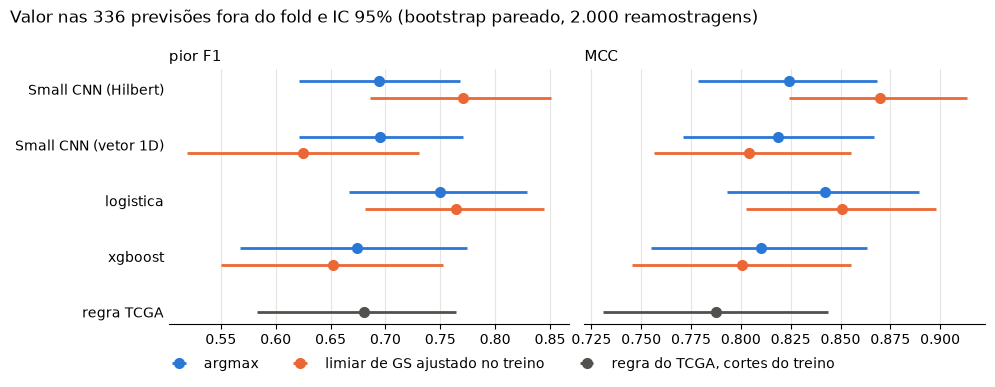

In [10]:
# pior F1 e MCC com IC 95%; uma cor por tipo de decisão (azul e laranja: par 1–2 da paleta validada; cinza neutro)
CORES = {"argmax": "#2a78d6", "limiar de GS ajustado no treino": "#eb6834", "regra do TCGA, cortes do treino": "#52514e"}
linhas = list(P) + ["regra TCGA"]
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, met in zip(eixos, ["pior F1", "MCC"]):
    for j, m in enumerate(linhas):
        variantes = ([("regra TCGA", "regra do TCGA, cortes do treino", 0)] if m == "regra TCGA" else
                     [(m, "argmax", -0.15), (f"{m} + limiar GS", "limiar de GS ajustado no treino", 0.15)])
        for nome, tipo, dy in variantes:
            v, (lo, hi) = tab.loc[nome, met], np.percentile(boot[nome][met], [2.5, 97.5])
            ax.errorbar(v, j + dy, xerr=[[v - lo], [hi - v]], fmt="o", ms=7, color=CORES[tipo], elinewidth=2, capsize=0,
                        label=tipo)
    ax.set_title(met, loc="left", fontsize=11)
    ax.grid(axis="x", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
eixos[0].set_yticks(range(len(linhas)), [{"cnn_hilbert": "Small CNN (Hilbert)", "cnn_vetor": "Small CNN (vetor 1D)"}.get(m, m)
                                        for m in linhas])
eixos[0].invert_yaxis()
legenda = dict(zip(*eixos[0].get_legend_handles_labels()[::-1]))
fig.legend(legenda.values(), legenda.keys(), loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Valor nas 336 previsões fora do fold e IC 95% (bootstrap pareado, 2.000 reamostragens)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(RESULTS / "05_eval_ic.png", dpi=150, bbox_inches="tight")

## Leitura do bloco A (execução de 2026-10-10; uma semente)

> **Atualização (bloco B, mesma data):** o ganho com o limiar de GS **não se repete** nas outras 4 sementes. A semente
> 42 foi a melhor das 5. As conclusões abaixo sobre o limiar valem só para ela; ver "Leitura do bloco B" no fim.

**No argmax, nenhum preditor se separa da Small CNN (Hilbert).**

| contra a Small CNN (Hilbert), pior F1 0,694 | diferença no pior F1 | IC 95% |
|---|---|---|
| Small CNN (vetor 1D) | +0,001 | −0,051 a +0,053 |
| logística | +0,056 | −0,009 a +0,120 |
| XGBoost | −0,020 | −0,119 a +0,074 |
| **regra do TCGA** (3 variáveis cruas) | −0,014 | −0,097 a +0,064 |

- Todos os IC contêm o 0. A logística é a que mais se aproxima de uma diferença real: fica acima em 96% dos
  sorteios.
- **A regra do TCGA empata com a Small CNN no argmax.** Três números por paciente (beta de CDKN2A, genes mutados e
  fração alterada) chegam ao mesmo pior-F1 que a imagem inteira. O MCC da regra é 0,037 menor (IC −0,087 a +0,014).
  Os cortes aprendidos são estáveis entre os folds: CDKN2A > 0,38–0,49, genes mutados > 302–310 e fração alterada
  < 0,015–0,043.
- **A Hilbert ordena melhor os GS** (AUC-PR 0,830 contra 0,766–0,788), mas sem significância: a diferença para a
  Small CNN (vetor 1D) é −0,064 (IC −0,144 a +0,013).

**Com o limiar de GS ajustado no treino, a Small CNN (Hilbert) passa a ser o melhor preditor.**

- Pior F1 de 0,694 para **0,771** (IC 0,69–0,85; ganho de +0,077, IC +0,005 a +0,152), e MCC de 0,824 para **0,870**.
  Os erros CIN→GS caem de 30 para 13, e os GS→CIN sobem de 3 para 8.
- **Supera a regra do TCGA** em +0,091 no pior F1 (IC +0,035 a +0,157) e em +0,082 no MCC (IC +0,040 a +0,130).
- Empata com a logística ajustada (diferença de 0,006, IC −0,052 a +0,061) e supera a Small CNN (vetor 1D) e o XGBoost
  ajustados.

**O ajuste não ajuda todos os modelos, e o motivo está na tabela "se p_GS cair".**

- Na Hilbert e na logística, a alternativa de 43 e 45 dos 46 GS é CIN. Baixar o p_GS só mexe na fronteira CIN × GS,
  que é onde está o erro.
- Na Small CNN (vetor 1D), a alternativa de 12 GS é **EBV**. Com o ajuste, 11 GS acabam em EBV (antes, 1), e o F1 de EBV cai de 0,918 para
  0,778. No fold 1, o peso escolhido no treino (0,20) zerou o GS do teste. No XGBoost, que já previa poucos GS
  (14 GS→CIN), o ajuste vai na outra direção (peso de até 6,3) e não melhora.
- Ou seja: a mesma rede, com os mesmos genes, separa GS de EBV melhor na Hilbert do que no vetor. É um indício a
  favor da dobra 2D, ainda com uma semente só.

**O que falta para afirmar:**

1. **Sementes (bloco B):** o ganho da Hilbert ajustada pode ser sorte de uma semente. As 5 sementes dizem se ele se
   repete.
2. **Otimismo do ajuste:** o peso é escolhido em previsões de modelos que tiveram o fold de teste no treino deles.
   Os rótulos do teste não entram, mas o IC pode estar um pouco otimista.
3. **Ablações (bloco B):** dizer qual canal sustenta a separação CIN × GS na Hilbert: só a CNV, como na regra do
   TCGA, ou também mutação e metilação.

# Bloco B — sementes e ablações por canal

Os treinos deste bloco estão no `04_models` (decisão do usuário, 2026-11-01); aqui as previsões gravadas são lidas.

Decisões do usuário (2026-10-10):
- **Sementes:** 5 no total nas duas Small CNN. A semente fixa os sorteios do treino (pesos iniciais, validação interna de
  15% e ordem dos lotes). A semente 42 é a do `04_models`, reaproveitada; entram 142, 242, 342 e 442. No fold `k`, a
  rede usa `semente + k`, como no `04_models`. A logística não sorteia nada, por isso não entra.
- **Ablações por canal na Small CNN (Hilbert) e na logística**, com a semente 42: só um canal (3 configurações) e tirando um
  canal (3 configurações). O canal retirado vira **0 depois de padronizar**, que é a média do treino: a rede e a
  logística continuam com a mesma entrada e o mesmo número de parâmetros, mas aquele canal não carrega informação.

As funções de padronização, imagem e treino são **cópias do `04_models`**, porque o notebook é autocontido. A célula
seguinte confere se a cópia reproduz o `04_models` no fold 0 da Small CNN (Hilbert), com a semente 42. É isso que permite
reaproveitar a semente 42 em vez de treinar de novo.

Custo previsto (8 CPUs, sem GPU): Small CNN (Hilbert) ~10 min por rodada de 5 folds, Small CNN (vetor 1D) ~25 min e
logística ~0,6 min.
São 4 sementes × (10 + 25) + 6 ablações × (10 + 0,6) ≈ **3 h 20**.

In [11]:
import json
import os
import time

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # silencia o log C++ do TF; erro Python continua aparecendo
import keras
import tensorflow as tf
from keras import layers
from scipy.special import softmax

tf.config.experimental.enable_op_determinism()  # mesma semente, mesmo resultado
CANAIS = ["mutacao", "cnv", "metilacao"]
padronizacao = {int(k): v for k, v in json.loads((PROCESSED / "padronizacao.json").read_text()).items()}
assert all(s["mutacao"].get("transformacao") == "log1p" for s in padronizacao.values())
LOG = RESULTS / "05_eval.log"  # o nbconvert só grava no fim: acompanhe por `tail -f results/05_eval.log`


def log(msg, tela=True):
    mem = {l.split(":")[0]: int(l.split()[1]) // 1024 for l in open("/proc/self/status") if l.startswith(("VmRSS", "VmHWM"))}
    linha = f"{time.strftime('%H:%M:%S')} [RAM {mem['VmRSS']} MB, pico {mem['VmHWM']} MB] {msg}"
    with open(LOG, "a") as f:
        f.write(linha + "\n")
    if tela:
        print(linha)


log("=== nova execução (bloco B) ===", tela=False)


# ---- cópia do 04_models: padronização e Hilbert, para os mapas do bloco C (os treinos estão no 04_models) ----
def transformar(x):
    x = x.copy()
    x[:, 0] = np.log1p(x[:, 0])  # mutação em log(1 + contagem), como no 03_images
    return x


def padronizar(x, stats):
    x = transformar(x)
    media = np.array([stats[c]["media"] for c in CANAIS], np.float32)[None, :, None]
    desvio = np.array([stats[c]["desvio"] for c in CANAIS], np.float32)[None, :, None]
    return np.nan_to_num((x - media) / desvio, nan=0.0)


FORMA = (layout.linha.max() + 1, layout.coluna.max() + 1)


def para_hilbert(x):
    img = np.zeros((x.shape[0], x.shape[1], *FORMA), np.float32)
    img[:, :, layout.linha, layout.coluna] = x
    return img


# ---- fim da cópia ----


FORMATOS = {"cnn_hilbert": lambda z: np.moveaxis(para_hilbert(z), 1, -1)}  # (n, 133, 134, 3): entrada dos modelos do bloco C
for k in range(K):
    assert np.allclose(padronizar(tensor[fold != k], padronizacao[k]).mean(axis=(0, 2)), 0, atol=1e-3), k


## Previsões dos experimentos

Treinadas no `04_models` (seção "Treinos que estavam no `05_eval`"), um arquivo por experimento e fold em
`results/oof_b/`. Experimentos: as sementes da Small CNN (Hilbert), as ablações na logística e na Small CNN (Hilbert) e as
sementes da Small CNN (vetor 1D).

In [12]:
OOF_B = RESULTS / "oof_b"  # previsões treinadas no 04_models (decisão do usuário, 2026-11-01)
SEMENTES = [SEED, 142, 242, 342, 442]
CONFIGS = {"so_mutacao": [0], "so_cnv": [1], "so_metilacao": [2],  # canais mantidos (0 mutação, 1 CNV, 2 metilação)
           "sem_mutacao": [1, 2], "sem_cnv": [0, 2], "sem_metilacao": [0, 1]}
EXPERIMENTOS = ([("cnn_hilbert", s, None) for s in SEMENTES[1:]]
                + [(m, SEED, c) for m in ["logistica", "cnn_hilbert"] for c in CONFIGS]
                + [("cnn_vetor", s, None) for s in SEMENTES[1:]])


def ler_oof(pasta, nome):
    # previsões fora do fold (336, 4), na ordem do coorte_cv.csv, gravadas pelo 04_models
    proba = np.empty((len(y), len(CLASSES)))
    for k in range(K):
        te = fold == k
        proba[te] = pd.read_csv(pasta / f"{nome}_fold{k}.csv").set_index("amostra").loc[coorte.amostra[te], PROBS].to_numpy()
    return proba


NOMES_B = [f"{m}_s{s}" + (f"_{c}" if c else "") for m, s, c in EXPERIMENTOS]
PB = {nome: ler_oof(OOF_B, nome) for nome in NOMES_B}
for m in ["cnn_hilbert", "cnn_vetor", "logistica"]:
    PB[f"{m}_s{SEED}"] = P[m]  # semente 42 com todos os canais = a do 04_models (predicoes_oof.csv)
assert all(np.allclose(p.sum(axis=1), 1, atol=1e-4) for p in PB.values())
log("bloco B: previsões lidas de results/oof_b/")

18:03:02 [RAM 757 MB, pico 990 MB] bloco B: previsões lidas de results/oof_b/


## Sementes: o ganho da Hilbert com o limiar de GS se repete?

Para cada semente, o mesmo procedimento do bloco A: argmax e limiar de GS escolhido no treino de cada fold.

In [13]:
def decisoes(p):
    # (argmax, limiar de GS escolhido no treino de cada fold), como no bloco A
    aj = np.empty_like(y)
    for k in range(K):
        aj[fold == k] = com_peso(p[fold == k], peso_gs(p[fold != k], y[fold != k]))
    return {"argmax": p.argmax(axis=1), "+ limiar GS": aj}


DEC = {nome: decisoes(p) for nome, p in PB.items()}
linhas = [{"modelo": m, "semente": s, "decisão": d, "AUC-PR GS": average_precision_score(y == GS, PB[f"{m}_s{s}"][:, GS]),
           **{k: float(v) for k, v in painel(confusoes(y, yp)[0]).items()}}
          for m in ["cnn_hilbert", "cnn_vetor"] for s in SEMENTES for d, yp in DEC[f"{m}_s{s}"].items()]
sementes = pd.DataFrame(linhas)
display(sementes.pivot_table(index=["modelo", "semente"], columns="decisão", values=["pior F1", "F1 GS", "F1 EBV", "MCC"]).round(3))
sementes.groupby(["modelo", "decisão"])[["pior F1", "F1 GS", "F1 EBV", "MCC", "AUC-PR GS"]].agg(["mean", "std", "min", "max"]).round(3)

F1 EBV              F1 GS                MCC         \
decisão             + limiar GS argmax + limiar GS argmax + limiar GS argmax   
modelo      semente                                                            
cnn_hilbert 42            0.918  0.897       0.771  0.694       0.870  0.824   
            142           0.833  0.857       0.653  0.696       0.775  0.801   
            242           0.929  0.929       0.629  0.667       0.801  0.834   
            342           0.828  0.828       0.736  0.722       0.828  0.827   
            442           0.951  0.951       0.557  0.660       0.769  0.816   
cnn_vetor   42            0.778  0.918       0.625  0.695       0.804  0.819   
            142           0.933  0.897       0.780  0.708       0.877  0.831   
            242           0.848  0.900       0.674  0.717       0.819  0.824   
            342           0.812  0.828       0.716  0.705       0.810  0.799   
            442           0.862  0.918       0.787  0.737       0.869  0.844   

                        pior F1         
decisão             + limiar GS argmax  
modelo      semente                     
cnn_hilbert 42            0.771  0.694  
            142           0.653  0.696  
            242           0.629  0.667  
            342           0.736  0.722  
            442           0.557  0.660  
cnn_vetor   42            0.625  0.695  
            142           0.780  0.708  
            242           0.674  0.717  
            342           0.716  0.705  
            442           0.787  0.737

pior F1                       F1 GS                \
                           mean    std    min    max   mean    std    min   
modelo      decisão                                                         
cnn_hilbert + limiar GS   0.669  0.086  0.557  0.771  0.669  0.086  0.557   
            argmax        0.688  0.025  0.660  0.722  0.688  0.025  0.660   
cnn_vetor   + limiar GS   0.716  0.069  0.625  0.787  0.716  0.069  0.625   
            argmax        0.712  0.016  0.695  0.737  0.712  0.016  0.695   

                               F1 EBV                         MCC         \
                           max   mean    std    min    max   mean    std   
modelo      decisão                                                        
cnn_hilbert + limiar GS  0.771  0.892  0.057  0.828  0.951  0.808  0.041   
            argmax       0.722  0.892  0.050  0.828  0.951  0.821  0.013   
cnn_vetor   + limiar GS  0.787  0.847  0.058  0.778  0.933  0.836  0.035   
            argmax       0.737  0.892  0.037  0.828  0.918  0.823  0.017   

                                      AUC-PR GS                       
                           min    max      mean    std    min    max  
modelo      decisão                                                   
cnn_hilbert + limiar GS  0.769  0.870     0.748  0.050  0.704  0.830  
            argmax       0.801  0.834     0.748  0.050  0.704  0.830  
cnn_vetor   + limiar GS  0.804  0.877     0.772  0.024  0.743  0.797  
            argmax       0.799  0.844     0.772  0.024  0.743  0.797

In [14]:
def dif(yp_a, yp_b, met="pior F1"):
    # diferença a − b nas 336 previsões e IC 95% pelo bootstrap pareado (os mesmos sorteios do bloco A)
    d = painel(confusoes(y, yp_a, idx))[met] - painel(confusoes(y, yp_b, idx))[met]
    lo, hi = np.percentile(d, [2.5, 97.5])
    return f"{painel(confusoes(y, yp_a)[0])[met] - painel(confusoes(y, yp_b)[0])[met]:+.3f} ({lo:+.3f} a {hi:+.3f})"


print("Diferença no pior F1, por semente da Small CNN, com IC 95% (a logística e a regra não dependem de semente):")
pd.DataFrame({s: {"Hilbert + limiar − Hilbert": dif(DEC[f"cnn_hilbert_s{s}"]["+ limiar GS"], DEC[f"cnn_hilbert_s{s}"]["argmax"]),
                  "Hilbert − regra TCGA": dif(DEC[f"cnn_hilbert_s{s}"]["argmax"], PRED["regra TCGA"]),
                  "Hilbert + limiar − regra TCGA": dif(DEC[f"cnn_hilbert_s{s}"]["+ limiar GS"], PRED["regra TCGA"]),
                  "Hilbert + limiar − logística + limiar": dif(DEC[f"cnn_hilbert_s{s}"]["+ limiar GS"], PRED["logistica + limiar GS"]),
                  "Hilbert + limiar − vetor + limiar": dif(DEC[f"cnn_hilbert_s{s}"]["+ limiar GS"], DEC[f"cnn_vetor_s{s}"]["+ limiar GS"]),
                  "logística − Hilbert": dif(PRED["logistica"], DEC[f"cnn_hilbert_s{s}"]["argmax"]),
                  "logística − vetor": dif(PRED["logistica"], DEC[f"cnn_vetor_s{s}"]["argmax"])}
              for s in SEMENTES}).T.rename_axis("semente")

Diferença no pior F1, por semente da Small CNN, com IC 95% (a logística e a regra não dependem de semente):


,Hilbert + limiar − Hilbert,Hilbert − regra TCGA,Hilbert + limiar − regra TCGA,Hilbert + limiar − logística + limiar,Hilbert + limiar − vetor + limiar,logística − Hilbert,logística − vetor
semente,,,,,,,
42,+0.077 (+0.005 a +0.152),+0.014 (-0.064 a +0.097),+0.091 (+0.035 a +0.157),+0.006 (-0.052 a +0.061),+0.146 (+0.045 a +0.252),+0.056 (-0.009 a +0.120),+0.055 (-0.000 a +0.108)
142,-0.043 (-0.109 a +0.017),+0.016 (-0.045 a +0.089),-0.027 (-0.124 a +0.074),-0.111 (-0.207 a -0.023),-0.127 (-0.205 a -0.059),+0.054 (-0.006 a +0.114),+0.042 (-0.011 a +0.095)
242,-0.038 (-0.099 a +0.027),-0.013 (-0.115 a +0.089),-0.051 (-0.137 a +0.041),-0.136 (-0.223 a -0.058),-0.046 (-0.160 a +0.072),+0.083 (-0.003 a +0.183),+0.033 (-0.031 a +0.094)
342,+0.014 (-0.041 a +0.073),+0.042 (-0.042 a +0.125),+0.056 (-0.020 a +0.131),-0.029 (-0.100 a +0.037),+0.020 (-0.057 a +0.110),+0.028 (-0.044 a +0.107),+0.045 (-0.025 a +0.109)
442,-0.103 (-0.188 a -0.033),-0.020 (-0.098 a +0.065),-0.123 (-0.229 a -0.013),-0.208 (-0.315 a -0.112),-0.230 (-0.341 a -0.114),+0.090 (+0.015 a +0.171),+0.013 (-0.040 a +0.062)


## Ablações por canal: qual ômica sustenta cada classe?

F1 por classe no argmax (semente 42), com todos os canais (`completo`) e em cada configuração. A segunda tabela dá a
diferença para o `completo`, com IC 95% pelo bootstrap pareado: se o IC fica abaixo do 0, a classe depende do canal
retirado.

In [15]:
ABL = {(m, c): DEC[f"{m}_s{SEED}" + ("" if c == "completo" else f"_{c}")]
       for m in ["cnn_hilbert", "logistica"] for c in ["completo", *CONFIGS]}
display(pd.DataFrame({chave: {**{k: float(v) for k, v in painel(confusoes(y, d["argmax"])[0]).items()},
                              "pior F1 + limiar GS": float(painel(confusoes(y, d["+ limiar GS"])[0])["pior F1"])}
                      for chave, d in ABL.items()}).T.drop(columns=["acurácia balanceada", "F1 macro"]).round(3))
pd.DataFrame({chave: {f"F1 {c}": dif(d["argmax"], ABL[(chave[0], "completo")]["argmax"], f"F1 {c}") for c in CLASSES}
              for chave, d in ABL.items() if chave[1] != "completo"}).T

MCC  pior F1  F1 CIN  F1 MSI  F1 GS  F1 EBV  \
cnn_hilbert completo       0.824    0.694   0.907   1.000  0.694   0.897   
            so_mutacao     0.538    0.146   0.789   0.983  0.441   0.146   
            so_cnv         0.598    0.433   0.891   0.617  0.600   0.433   
            so_metilacao   0.487    0.509   0.707   0.509  0.529   0.875   
            sem_mutacao    0.674    0.637   0.868   0.689  0.637   0.847   
            sem_cnv        0.713    0.500   0.846   0.983  0.500   0.949   
            sem_metilacao  0.673    0.351   0.867   0.974  0.590   0.351   
logistica   completo       0.842    0.750   0.924   0.956  0.750   0.951   
            so_mutacao     0.572    0.432   0.808   0.929  0.475   0.432   
            so_cnv         0.536    0.500   0.859   0.539  0.500   0.500   
            so_metilacao   0.796    0.723   0.908   0.870  0.723   0.967   
            sem_mutacao    0.759    0.653   0.897   0.833  0.653   0.967   
            sem_cnv        0.796    0.645   0.906   0.957  0.645   0.933   
            sem_metilacao  0.766    0.615   0.903   0.938  0.750   0.615   

                           pior F1 + limiar GS  
cnn_hilbert completo                     0.771  
            so_mutacao                   0.207  
            so_cnv                       0.429  
            so_metilacao                 0.477  
            sem_mutacao                  0.615  
            sem_cnv                      0.547  
            sem_metilacao                0.378  
logistica   completo                     0.765  
            so_mutacao                   0.432  
            so_cnv                       0.509  
            so_metilacao                 0.733  
            sem_mutacao                  0.667  
            sem_cnv                      0.612  
            sem_metilacao                0.643

F1 CIN                    F1 MSI  \
cnn_hilbert so_mutacao     -0.118 (-0.163 a -0.075)  -0.017 (-0.041 a +0.000)   
            so_cnv         -0.016 (-0.044 a +0.012)  -0.383 (-0.491 a -0.278)   
            so_metilacao   -0.199 (-0.256 a -0.148)  -0.491 (-0.569 a -0.412)   
            sem_mutacao    -0.039 (-0.061 a -0.018)  -0.311 (-0.405 a -0.226)   
            sem_cnv        -0.061 (-0.095 a -0.025)  -0.017 (-0.043 a +0.000)   
            sem_metilacao  -0.040 (-0.068 a -0.013)  -0.026 (-0.061 a +0.000)   
logistica   so_mutacao     -0.116 (-0.157 a -0.076)  -0.027 (-0.077 a +0.020)   
            so_cnv         -0.064 (-0.101 a -0.033)  -0.417 (-0.523 a -0.309)   
            so_metilacao   -0.016 (-0.040 a +0.006)  -0.086 (-0.146 a -0.031)   
            sem_mutacao    -0.027 (-0.050 a -0.008)  -0.122 (-0.189 a -0.061)   
            sem_cnv        -0.018 (-0.042 a +0.005)  +0.001 (-0.042 a +0.047)   
            sem_metilacao  -0.021 (-0.039 a -0.003)  -0.018 (-0.055 a +0.019)   

                                              F1 GS                    F1 EBV  
cnn_hilbert so_mutacao     -0.254 (-0.365 a -0.151)  -0.750 (-0.897 a -0.587)  
            so_cnv         -0.094 (-0.190 a -0.006)  -0.463 (-0.628 a -0.305)  
            so_metilacao   -0.165 (-0.283 a -0.058)  -0.022 (-0.113 a +0.073)  
            sem_mutacao    -0.057 (-0.126 a +0.011)  -0.049 (-0.129 a +0.025)  
            sem_cnv        -0.194 (-0.300 a -0.092)  +0.053 (-0.033 a +0.145)  
            sem_metilacao  -0.104 (-0.181 a -0.032)  -0.546 (-0.705 a -0.375)  
logistica   so_mutacao     -0.275 (-0.393 a -0.169)  -0.518 (-0.724 a -0.321)  
            so_cnv         -0.250 (-0.345 a -0.149)  -0.451 (-0.583 a -0.324)  
            so_metilacao   -0.027 (-0.112 a +0.052)  +0.016 (+0.000 a +0.048)  
            sem_mutacao    -0.097 (-0.187 a -0.019)  +0.016 (+0.000 a +0.049)  
            sem_cnv        -0.105 (-0.203 a -0.012)  -0.017 (-0.054 a +0.000)  
            sem_metilacao  +0.000 (-0.037 a +0.040)  -0.335 (-0.496 a -0.192)

## Leitura do bloco B (execução de 2026-10-10)

**1. O ganho da Hilbert com o limiar de GS foi sorte da semente 42.**

| pior F1 | 42 | 142 | 242 | 342 | 442 | média ± desvio |
|---|---|---|---|---|---|---|
| Small CNN (Hilbert), argmax | 0,694 | 0,696 | 0,667 | 0,722 | 0,660 | 0,688 ± 0,025 |
| Small CNN (Hilbert) + limiar GS | **0,771** | 0,653 | 0,629 | 0,736 | 0,557 | 0,669 ± 0,086 |
| Small CNN (vetor 1D), argmax | 0,695 | 0,708 | 0,717 | 0,705 | 0,737 | 0,712 ± 0,016 |
| Small CNN (vetor 1D) + limiar GS | 0,625 | 0,780 | 0,674 | 0,716 | 0,787 | 0,716 ± 0,069 |

Sem semente: logística 0,750 (+ limiar 0,765) e regra do TCGA 0,680.

- Na Hilbert, o limiar piora 3 das 5 sementes. Na 442 a perda é consistente: −0,103, IC −0,188 a −0,033. A vantagem
  sobre a regra do TCGA só aparece na semente 42, e na 442 a Hilbert ajustada perde para a regra (−0,123, IC −0,229 a
  −0,013).
- O limiar **aumenta a variação entre sementes**: o desvio passa de 0,025 para 0,086 na Hilbert e de 0,016 para 0,069
  no vetor. O peso é escolhido com uns 37 GS de treino, e mudanças pequenas nas probabilidades mudam o peso escolhido.
- A observação do bloco A sobre a Small CNN (vetor 1D), de que o ajuste empurra GS para EBV, também era da semente 42. Nas sementes 142
  e 442, o limiar melhora o vetor (0,780 e 0,787).
- O AUC-PR de GS também varia: 0,704–0,830 na Hilbert e 0,743–0,797 no vetor. O 0,830 do bloco A foi a melhor semente.

**2. No argmax, a Small CNN (Hilbert) empata com a regra do TCGA e com a Small CNN (vetor 1D). A logística fica acima das duas.**

- Hilbert − regra do TCGA: de −0,020 a +0,042 nas 5 sementes, sempre com o IC contendo o 0. Os três números da regra
  chegam ao mesmo pior F1 que a imagem.
- Hilbert × vetor: 0,688 ± 0,025 contra 0,712 ± 0,016. Não há sinal de que a dobra 2D ajude.
- A logística (0,750) fica acima das 10 execuções da Small CNN (a melhor chega a 0,737):
  - logística − Hilbert: de +0,028 a +0,090 (o IC exclui o 0 só na semente 442);
  - logística − vetor: de +0,013 a +0,055 (nenhum IC exclui o 0).

  A direção é sempre a mesma, mas cada diferença, sozinha, não é conclusiva.

**3. Ablações (semente 42, argmax): cada classe depende de um canal, e nenhum canal sozinho dá conta das quatro.**

| classe | canal | Small CNN (Hilbert): F1 ao tirar o canal | logística: F1 ao tirar o canal |
|---|---|---|---|
| MSI | mutação | −0,311 (IC −0,405 a −0,226) | −0,122 (−0,189 a −0,061) |
| EBV | metilação | −0,546 (−0,705 a −0,375) | −0,335 (−0,496 a −0,192) |
| GS | CNV | −0,194 (−0,300 a −0,092) | −0,105 (−0,203 a −0,012) |
| GS | metilação | −0,104 (−0,181 a −0,032) | 0,000 (−0,037 a +0,040) |

- **É a assinatura do TCGA, canal a canal:** hipermutação no MSI, metilação (CIMP) no EBV e CNV na fronteira GS × CIN.
  Na Hilbert, tirar um canal que não é o da classe mexe pouco nela (MSI sem CNV ou sem metilação: ≥ 0,97).
- **Com um canal só, a Hilbert perde alguma classe:**
  - só mutação: EBV com F1 0,146;
  - só CNV: EBV 0,433 e MSI 0,617;
  - só metilação: MSI 0,509 e GS 0,529.

  O pior F1 completo (0,694) é maior que o das 6 ablações (0,146 a 0,637). É o padrão dos métodos de uma ômica só que
  motivou o projeto: cada um capta parte das classes. Juntar os três canais resolve isso.
- **Exceção: a logística só com metilação** chega a pior F1 0,723, contra 0,750 com tudo (GS −0,027, IC −0,112 a
  +0,052). Ela tira MSI (0,870) e GS (0,723) da metilação, e a Small CNN não (0,509 e 0,529). Hipótese a conferir no bloco C:
  esses sinais estão em genes isolados (como o MLH1, um pixel entre 17.818). A logística tem um peso por gene, e a Small CNN
  agrega vizinhanças.
- As ablações são de uma semente só. O desvio entre sementes no pior F1 (argmax) é 0,025. Os efeitos acima de 0,1 estão
  muito acima desse ruído; o de GS sem mutação na Hilbert (−0,057, IC contendo o 0), não.

**O que isso muda para a pergunta de pesquisa:**

- **A favor:** os três canais juntos preservam a assinatura de cada classe. Cada ômica sustenta uma classe, e só a
  combinação tem o melhor pior F1.
- **Contra:** até aqui, o ganho vem de **combinar as três ômicas**, não do formato de imagem. A Small CNN (Hilbert) empata com o
  vetor 1D e com a regra do TCGA, e fica abaixo da logística no tensor achatado.
- **Próximo: bloco C** (Grad-CAM na Hilbert). Pergunta: a Small CNN usa MLH1, CDKN2A e os blocos de CNV?


# Bloco C — para onde a Small CNN (Hilbert) olha (Grad-CAM)

Pergunta: para dizer a classe de um paciente, a rede usa as assinaturas do TCGA (MLH1 no MSI, CDKN2A no EBV, blocos de
CNV no CIN), ou outra coisa?

- **Grad-CAM:** pega a última camada convolucional, pesa cada um dos 64 mapas pelo gradiente médio do escore da
  classe e soma. O resultado é um mapa de "onde está a evidência" para aquela classe. Nesta rede a última camada tem
  **16 × 16**, então cada célula cobre uns 70 pixels da imagem de 133 × 134. Na Hilbert isso é uma região contínua do
  genoma, de uns 70 genes vizinhos, e não um gene. O mapa é ampliado para 133 × 134 e lido gene a gene pelo
  `layout_hilbert.csv`.
- **Gradiente × entrada (complemento):** é o gradiente do escore em relação a cada pixel e canal, multiplicado pelo
  valor do pixel. Dá a atribuição **por gene e por canal**, coisa que o Grad-CAM, com resolução de ~70 genes, não
  dá. Positivo = empurra para a classe. O ponto de referência é o 0, que depois de padronizar é a média do treino: um
  gene com valor perto da média recebe pouca atribuição, mesmo que essa "normalidade" seja informativa (é o caso da
  CNV plana dos GS).
- **Escore:** o logit da classe verdadeira do paciente, antes do softmax. Cada paciente é explicado pelo modelo do
  fold em que ele foi teste, ou seja, por um modelo que nunca o viu.
- **Modelos:** os do `04_models` não foram salvos. A Small CNN (Hilbert) é retreinada com a semente 42, igual ao `04_models`
  (a conferência do bloco B mostrou que a cópia reproduz o treino), e os 5 modelos ficam em `results/modelos_c/`. Numa
  nova execução eles são reaproveitados; apague a pasta para treinar de novo (~13 min).

In [16]:
MODELOS = RESULTS / "modelos_c"  # os 5 modelos da Small CNN (Hilbert), semente 42, salvos pelo 04_models (2026-11-01)
assert all((MODELOS / f"cnn_hilbert_s{SEED}_fold{k}.keras").exists() for k in range(K)), "rode o 04_models, que salva os modelos"

In [17]:
def explicar(modelo, x, alvo, lote=16):
    # Grad-CAM na última camada convolucional (ReLU do 4º bloco) e gradiente × entrada, para o logit da classe `alvo`
    relu = [l for l in modelo.layers if isinstance(l, layers.ReLU)][-1]
    duplo = keras.Model(modelo.inputs, [relu.output, modelo.output])
    cams, gxes, logits_ = [], [], []
    for i in range(0, len(x), lote):
        xb, ab = tf.convert_to_tensor(x[i:i + lote]), tf.convert_to_tensor(alvo[i:i + lote])
        with tf.GradientTape(persistent=True) as fita:
            fita.watch(xb)
            mapas, logits = duplo(xb, training=False)
            escore = tf.gather(logits, ab, batch_dims=1)
        g_mapas, g_x = fita.gradient(escore, [mapas, xb])
        del fita
        cam = tf.nn.relu(tf.reduce_sum(mapas * tf.reduce_mean(g_mapas, axis=(1, 2), keepdims=True), axis=-1))
        cams.append(tf.image.resize(cam[..., None], FORMA, method="bilinear")[..., 0].numpy())
        gxes.append((g_x * xb).numpy())
        logits_.append(logits.numpy())
    cam = np.concatenate(cams)
    cam /= np.maximum(cam.max(axis=(1, 2), keepdims=True), 1e-12)  # cada paciente com máximo 1
    return cam, np.concatenate(gxes), np.concatenate(logits_), tuple(mapas.shape[1:3])


CAM = np.empty((len(y), *FORMA), np.float32)    # Grad-CAM, um mapa por paciente
GXE = np.empty((len(y), *FORMA, 3), np.float32)  # gradiente × entrada, por pixel e canal
for k in range(K):
    te = fold == k
    modelo = keras.models.load_model(MODELOS / f"cnn_hilbert_s{SEED}_fold{k}.keras")
    x = FORMATOS["cnn_hilbert"](padronizar(tensor[te], padronizacao[k]))
    CAM[te], GXE[te], logits, res = explicar(modelo, x, y[te])
    # autoteste: a função devolve os logits do próprio modelo, e o modelo guardado reproduz o 04_models
    assert np.allclose(logits, modelo(x, training=False).numpy(), atol=1e-4), k
    assert np.abs(softmax(logits, axis=1) - P["cnn_hilbert"][te]).max() < 1e-3, k
    # autoteste: o gradiente de um paciente não depende dos outros do lote
    c1, g1, _, _ = explicar(modelo, x[:1], y[te][:1])
    assert np.allclose(c1, CAM[te][:1], atol=1e-5) and np.allclose(g1, GXE[te][:1], atol=1e-5), k
    del x
log(f"bloco C: Grad-CAM na camada de {res[0]} × {res[1]}; cada célula cobre ~{FORMA[0] * FORMA[1] / (res[0] * res[1]):.0f} pixels")

18:03:24 [RAM 975 MB, pico 1433 MB] bloco C: Grad-CAM na camada de 16 × 16; cada célula cobre ~70 pixels


## Mapas médios por classe

Cada coluna é a **média das amostras de uma classe verdadeira** (uma amostra de tumor por paciente), e isso vale para os dois
blocos da figura. Em cima, o Grad-CAM (0 a 1). Embaixo, o gradiente × entrada em cada canal, nas mesmas amostras (vermelho
empurra para a classe, azul afasta). As linhas finas cinza separam os cromossomos. Os marcadores são os genes que o TCGA
(2014) associa a cada classe: MLH1 (○) e CDKN2A (□) na metilação, ERBB2 (△) na CNV, TP53 (◇) na mutação e, para o GS, CDH1
(▽) e RHOA (⬠) na mutação (os dois do GS foram acrescentados em 2026-10-30).

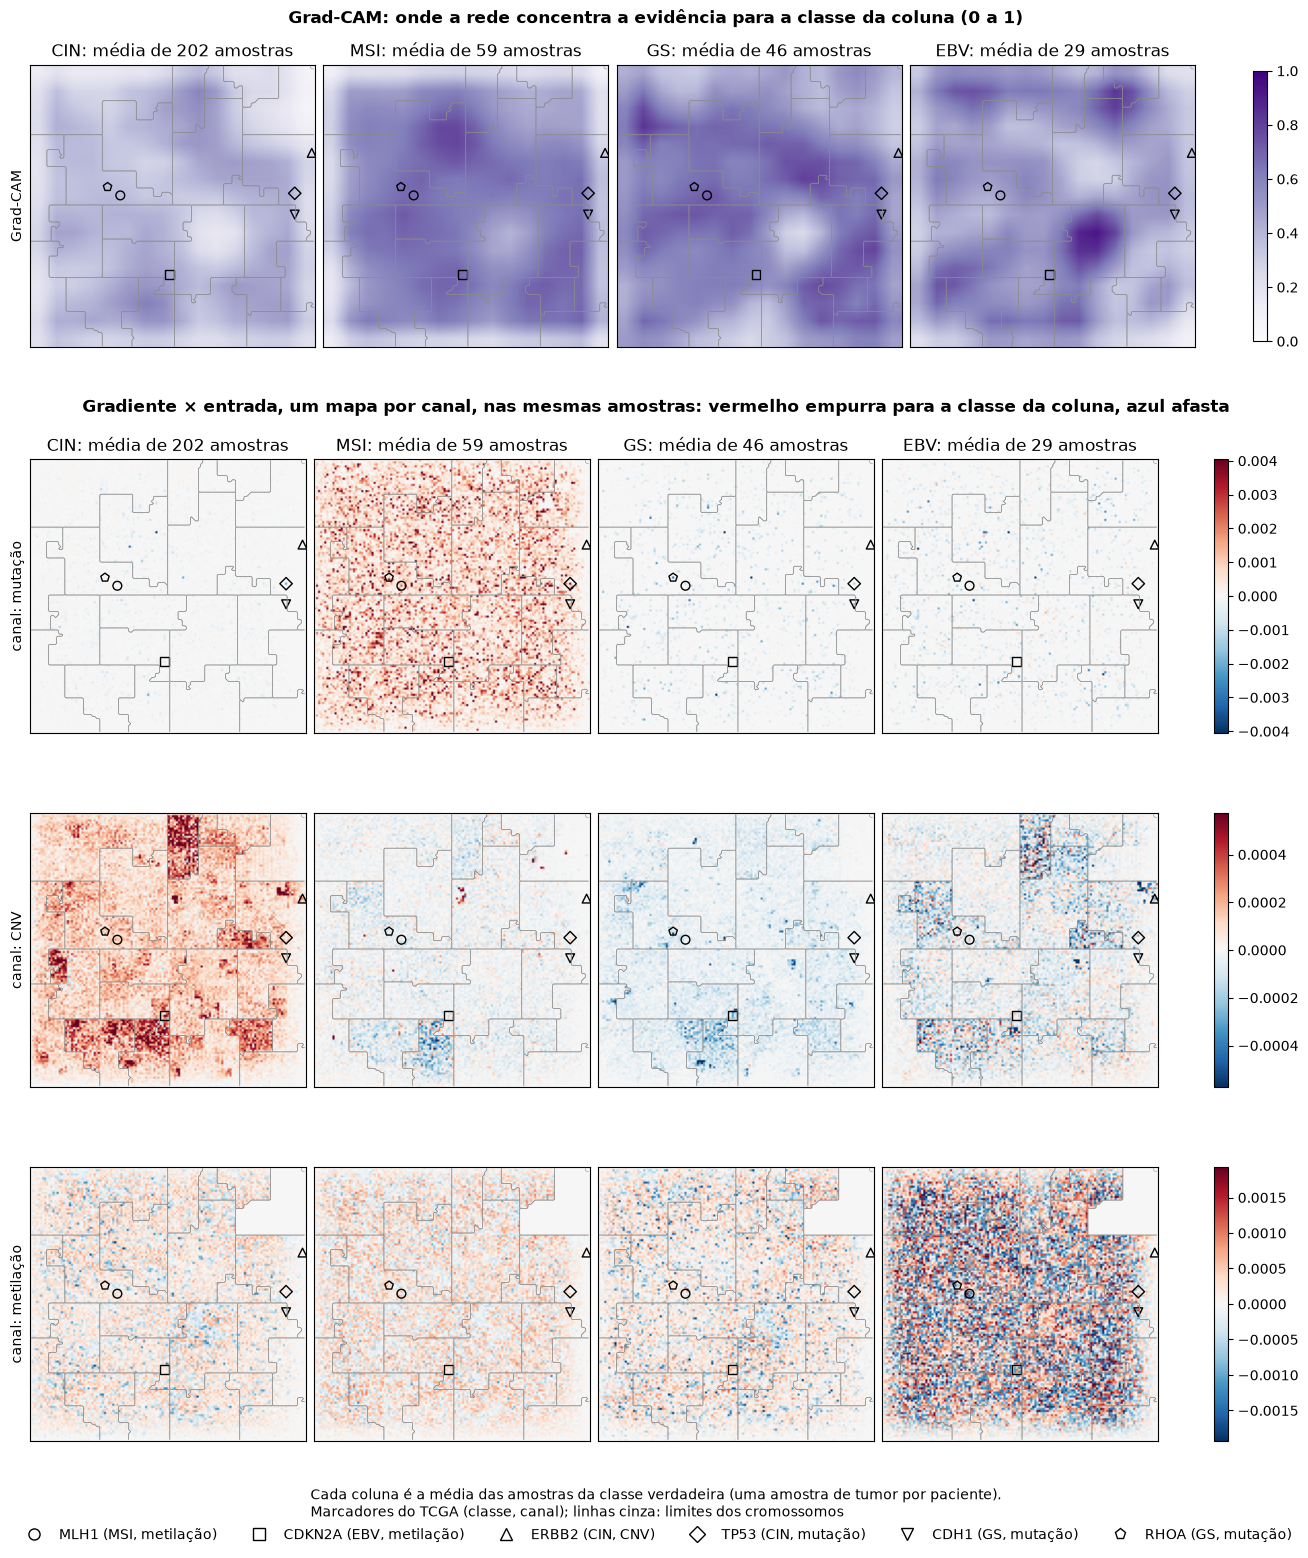

In [18]:
genes = pd.read_csv(RAIZ / "data" / "interim" / "genes.csv")[["gene", "cromossomo"]]
assert (genes.gene.to_numpy() == layout.gene.to_numpy()).all()
lin, col = layout.linha.to_numpy(), layout.coluna.to_numpy()
crom = np.full(FORMA, np.nan)
crom[lin, col] = genes.cromossomo.replace({"X": "23"}).astype(int)
# marcadores do TCGA (2014): símbolo, classe e canal em que cada um age
MARCADORES = {"MLH1": ("o", "MSI", "metilação"), "CDKN2A": ("s", "EBV", "metilação"), "ERBB2": ("^", "CIN", "CNV"),
              "TP53": ("D", "CIN", "mutação"), "CDH1": ("v", "GS", "mutação"), "RHOA": ("p", "GS", "mutação")}
pos = layout.set_index("gene")
n = dict(zip(CLASSES, np.bincount(y)))
CAM_MEDIO = {c: CAM[y == i].mean(axis=0) for i, c in enumerate(CLASSES)}  # cada coluna da figura: média das amostras da classe
GXE_MEDIO = {c: GXE[y == i].mean(axis=0) for i, c in enumerate(CLASSES)}


def mapa(ax, img, **kw):
    im = ax.imshow(img, **kw)
    for k in range(1, 24):  # limites dos cromossomos, um contorno por cromossomo para todos terem a mesma espessura
        ax.contour(crom == k, levels=[0.5], colors="0.55", linewidths=0.4)
    for g, (mk, _, _) in MARCADORES.items():
        ax.scatter(pos.loc[g, "coluna"], pos.loc[g, "linha"], marker=mk, s=40, facecolors="none", edgecolors="k", linewidths=1)
    ax.set(xticks=[], yticks=[])
    return im


fig = plt.figure(figsize=(13, 15.5), layout="constrained")
cima, baixo = fig.subfigures(2, 1, height_ratios=[1, 3.1])
cima.suptitle("Grad-CAM: onde a rede concentra a evidência para a classe da coluna (0 a 1)", fontweight="bold")
axs = cima.subplots(1, 4)
for i, c in enumerate(CLASSES):
    im = mapa(axs[i], CAM_MEDIO[c], cmap="Purples", vmin=0, vmax=1)
    axs[i].set_title(f"{c}: média de {n[c]} amostras")
axs[0].set_ylabel("Grad-CAM")
cima.colorbar(im, ax=axs, shrink=0.8)

baixo.suptitle("Gradiente × entrada, um mapa por canal, nas mesmas amostras: vermelho empurra para a classe da coluna, azul afasta",
               fontweight="bold")
axs = baixo.subplots(3, 4)
for j, rotulo in enumerate(["mutação", "CNV", "metilação"]):
    lim = np.percentile(np.abs([GXE_MEDIO[c][..., j] for c in CLASSES]), 99.5)  # escala própria de cada canal
    for i, c in enumerate(CLASSES):
        im = mapa(axs[j, i], GXE_MEDIO[c][..., j], cmap="RdBu_r", vmin=-lim, vmax=lim)
        if j == 0:
            axs[j, i].set_title(f"{c}: média de {n[c]} amostras")
    axs[j, 0].set_ylabel(f"canal: {rotulo}")
    baixo.colorbar(im, ax=axs[j, :], shrink=0.8)
legenda = [plt.Line2D([], [], marker=mk, ls="", mfc="none", mec="k", ms=8, label=f"{g} ({cl}, {canal})")
           for g, (mk, cl, canal) in MARCADORES.items()]
baixo.legend(handles=legenda, loc="outside lower center", ncols=6, frameon=False,
             title="Cada coluna é a média das amostras da classe verdadeira (uma amostra de tumor por paciente).\n"
                   "Marcadores do TCGA (classe, canal); linhas cinza: limites dos cromossomos")
fig.savefig(RESULTS / "05_eval_gradcam.png", dpi=110)
plt.show()

## Genes, canais e cromossomos

1. **Quanto de cada canal a rede usa** por classe: soma de |gradiente × entrada| em cada canal, como fração do total do
   paciente, na média da classe. Para comparar com as ablações do bloco B.
2. **Marcadores:** percentil de cada gene entre os 17.818 (100 = o mais alto), no Grad-CAM e no gradiente × entrada do
   canal em que o marcador age.
3. **Os 10 genes com maior atribuição** (gradiente × entrada somado nos 3 canais) em cada classe, com a parte de cada
   canal.
4. **Os 5 cromossomos com maior Grad-CAM médio** em cada classe.

A tabela gene a gene completa vai para `results/05_eval_gradcam_genes.csv`.

In [19]:
cam_gene = {c: CAM[y == i][:, lin, col].mean(axis=0) for i, c in enumerate(CLASSES)}  # (17818,)
gxe_gene = {c: GXE[y == i][:, lin, col].mean(axis=0) for i, c in enumerate(CLASSES)}  # (17818, 3)
genes.assign(**{f"gradcam_{c}": cam_gene[c] for c in CLASSES},
             **{f"gxe_{c}_{CANAIS[j]}": gxe_gene[c][:, j] for c in CLASSES for j in range(3)}
             ).to_csv(RESULTS / "05_eval_gradcam_genes.csv", index=False)

soma = np.abs(GXE).sum(axis=(1, 2))  # (336, 3)
print("1. Fração de |gradiente × entrada| em cada canal (média dos pacientes da classe):")
display(pd.DataFrame(soma / soma.sum(axis=1, keepdims=True), columns=CANAIS).groupby(np.array(CLASSES)[y]).mean().loc[CLASSES].round(3))

def percentil(v, g):
    return 100 * (v < v[genes.gene.eq(g).to_numpy()][0]).mean()

CANAL_DO_MARCADOR = {"MLH1": 2, "CDKN2A": 2, "ERBB2": 1, "TP53": 0, "CDH1": 0, "RHOA": 0}
print("2. Percentil dos marcadores (Grad-CAM | gradiente × entrada no canal do marcador):")
display(pd.DataFrame({f"{g} ({CANAIS[j]})": {c: f"{percentil(cam_gene[c], g):.0f} | {percentil(gxe_gene[c][:, j], g):.0f}" for c in CLASSES}
                      for g, j in CANAL_DO_MARCADOR.items()}))

print("3. Os 10 genes com maior gradiente × entrada (soma dos canais) em cada classe:")
top = []
for c in CLASSES:
    tot = gxe_gene[c].sum(axis=1)
    for r, g in enumerate(np.argsort(-tot)[:10]):
        top.append({"classe": c, "#": r + 1, "gene": genes.gene[g], "cromossomo": genes.cromossomo[g], "total": tot[g],
                    **dict(zip(CANAIS, gxe_gene[c][g]))})
display(pd.DataFrame(top).set_index(["classe", "#"]).round(3))

print("4. Os 5 cromossomos com maior Grad-CAM médio em cada classe:")
por_crom = pd.DataFrame(cam_gene).groupby(genes.cromossomo).mean()
pd.DataFrame({c: [f"{k} ({v:.2f})" for k, v in por_crom[c].nlargest(5).items()] for c in CLASSES}, index=range(1, 6))

1. Fração de |gradiente × entrada| em cada canal (média dos pacientes da classe):


,mutacao,cnv,metilacao
CIN,0.112,0.402,0.487
MSI,0.536,0.109,0.355
GS,0.153,0.125,0.722
EBV,0.121,0.188,0.691


2. Percentil dos marcadores (Grad-CAM | gradiente × entrada no canal do marcador):


,MLH1 (metilacao),CDKN2A (metilacao),ERBB2 (cnv),TP53 (mutacao),CDH1 (mutacao),RHOA (mutacao)
CIN,55 | 64,85 | 54,11 | 89,51 | 0,49 | 1,53 | 85
MSI,88 | 27,86 | 36,12 | 60,44 | 99,45 | 83,84 | 76
GS,93 | 58,48 | 67,9 | 39,51 | 0,53 | 0,79 | 0
EBV,41 | 21,63 | 90,10 | 3,44 | 11,37 | 6,40 | 9


3. Os 10 genes com maior gradiente × entrada (soma dos canais) em cada classe:


gene cromossomo  total  mutacao    cnv  metilacao
classe #                                                        
CIN    1       URI1         19  0.002   -0.000  0.002      0.001
       2       POP4         19  0.002   -0.000  0.002      0.001
       3      CCNE1         19  0.002   -0.000  0.002      0.000
       4     ANKIB1          7  0.002    0.000  0.002      0.000
       5        MYC          8  0.002   -0.000  0.001      0.001
       6   C19orf12         19  0.002    0.000  0.002      0.000
       7     PABPC1          8  0.002    0.000  0.001      0.001
       8      ACOT8         20  0.002    0.000  0.001      0.001
       9     SEC61G          7  0.002    0.000  0.002      0.000
       10      EGFR          7  0.002   -0.000  0.002     -0.000
MSI    1        TTN          2  0.098    0.098  0.000     -0.001
       2      MUC16         19  0.025    0.025  0.000     -0.000
       3       PLEC          8  0.020    0.020  0.000     -0.000
       4      KMT2B         19  0.016    0.016 -0.000      0.001
       5      LRP1B          2  0.016    0.016 -0.000     -0.000
       6     ARID1A          1  0.015    0.015  0.000      0.000
       7        DMD          X  0.014    0.014  0.000      0.000
       8      FCGBP         19  0.012    0.013 -0.000     -0.000
       9       RYR1         19  0.012    0.012 -0.000      0.000
       10      PCLO          7  0.012    0.012 -0.000     -0.000
GS     1   ATP6V1E1         22  0.001   -0.000 -0.000      0.001
       2      CEP57         11  0.001   -0.000 -0.000      0.001
       3      KAT2B          3  0.001    0.000 -0.000      0.001
       4     TRIM25         17  0.001   -0.000 -0.000      0.001
       5      PTRH2         17  0.001    0.000 -0.000      0.001
       6    CENATAC         11  0.001    0.000  0.000      0.001
       7      FARS2          6  0.001    0.000 -0.000      0.001
       8       POP1          8  0.001   -0.000 -0.000      0.001
       9      PRKCE          2  0.001    0.000 -0.000      0.001
       10    FAM76B         11  0.001    0.000 -0.000      0.001
EBV    1      CMTM1         16  0.004   -0.000 -0.000      0.004
       2    SLC26A8          6  0.004    0.000  0.000      0.003
       3       CSH1         17  0.003   -0.000 -0.000      0.003
       4       ASPN          9  0.003   -0.000 -0.000      0.003
       5       LYG1          2  0.003    0.000 -0.000      0.003
       6      CRYGS          3  0.003   -0.000 -0.000      0.003
       7      VN1R1         19  0.003   -0.000 -0.000      0.003
       8       LCN6          9  0.003    0.000  0.000      0.003
       9       URAD         13  0.003   -0.000  0.000      0.003
       10   SPATA45          1  0.003   -0.000  0.000      0.003

4. Os 5 cromossomos com maior Grad-CAM médio em cada classe:


,CIN,MSI,GS,EBV
1,13 (0.48),13 (0.68),13 (0.68),11 (0.69)
2,20 (0.47),2 (0.68),18 (0.67),21 (0.60)
3,8 (0.46),9 (0.66),16 (0.67),7 (0.58)
4,9 (0.43),10 (0.65),10 (0.65),8 (0.55)
5,19 (0.42),16 (0.64),3 (0.64),9 (0.55)


## Leitura do bloco C (execução de 2026-10-10; semente 42)

**1. Nesta rede, o Grad-CAM quase não localiza nada.**

- A rede reduz a imagem 4 vezes, e a última camada tem 16 × 16. Cada célula cobre uns 70 genes.
- Os mapas médios de CIN, MSI e GS se parecem (correlação gene a gene de 0,61 a 0,75 entre eles).
- Os marcadores não se destacam de forma específica: a região do MLH1 fica no percentil 88 no MSI, mas no 93 no GS,
  e a do ERBB2 fica entre os percentis 9 e 12 em todas as classes.
- A exceção é o EBV, com uma mancha no 11q12: 195 dos 200 genes de maior Grad-CAM estão lá (receptores olfativos,
  GLYAT, FAM111A/B). Não é um marcador conhecido do EBV, e com 29 pacientes pode ser acaso. Fica como achado a
  conferir.

**2. O gradiente × entrada mostra cada assinatura, no canal certo.**

| classe | fração da atribuição por canal (mut. · CNV · metil.) | o que a rede usa |
|---|---|---|
| MSI | **0,54** · 0,11 · 0,36 | Mutações no genoma inteiro: cada gene mutado empurra para MSI. Os genes do topo são TTN, MUC16, PLEC, LRP1B, DMD, RYR1 e PCLO, a maioria longos, que acumulam mutações num tumor hipermutado. É a carga mutacional, não um gene específico. |
| CIN | 0,11 · **0,40** · **0,49** | Blocos de CNV (manchas vermelhas contínuas no canal de CNV). Os 10 genes do topo são de amplicons focais: CCNE1 e seus vizinhos POP4, C19orf12 e URI1 (19q12, todos dentro de 0,3 Mb), EGFR e SEC61G (7p11), MYC e PABPC1 (8q) e ACOT8 (20q). O ERBB2 fica no percentil 89 do canal de CNV. |
| EBV | 0,12 · 0,19 · **0,69** | Hipermetilação espalhada pelo genoma (CIMP). O CDKN2A fica no percentil 90, mas os genes do topo são variados: o sinal é o conjunto, não um gene. |
| GS | 0,15 · 0,13 · **0,72** | Valores muito pequenos (no topo, ~100 vezes menores que os do MSI). Ver o item 3. |

**3. O GS aparece pela ausência.**

- No canal de CNV do GS, o mapa é azul: qualquer alteração de número de cópias afasta o paciente da classe.
- O gradiente × entrada mede o desvio em relação à média do treino. Um genoma plano fica perto da média e não recebe
  atribuição positiva.
- Por isso, a prova de que o GS depende da CNV vem da ablação (−0,194 sem a CNV), e não deste mapa.
- **Marcadores do GS (acrescentados em 2026-10-30):** CDH1 e RHOA estão mutados em 28% e 13% das amostras GS, mais que
  nas outras classes (3–17% e 3–7%). Mesmo assim, a mutação deles está entre as que mais afastam do GS: entre os 17.818
  genes, o RHOA é o 5º mais negativo e o CDH1 o 26º (percentil 0 na tabela 2). A rede não aprendeu esses marcadores: dos
  2.230 genes mutados em algum GS, 89% têm atribuição negativa para a classe. Para ela, mutação afasta do GS.

**4. Pontos que conversam com o bloco B:**

- **A rede não usa o MLH1.** No MSI, a metilação do MLH1 fica no percentil 27, e a rede reconhece a classe pela
  carga mutacional. Isso explica a ablação: só com metilação, a Small CNN acerta pouco o MSI (0,509), e a logística acerta
  bem (0,870). A logística tem um peso só para o pixel do MLH1, e a Small CNN, que agrega vizinhanças, não aproveita um
  sinal que está num pixel só.
- **Para a rede, qualquer mutação aponta para MSI.** O TP53 é frequente no CIN, mas a mutação dele tem a atribuição
  mais negativa para CIN entre os 17.818 genes (percentil 0). A rede não aprendeu o TP53 como marcador do CIN, e sim
  que "muita mutação → MSI".
- **A vizinhança no genoma importa para a CNV.** O sinal do CIN está em blocos de genes vizinhos (amplicons), que é
  justamente o que a curva de Hilbert junta. Mesmo assim, o bloco B mostrou que a Small CNN (vetor 1D) chega ao mesmo pior
  F1, porque a convolução 1D também enxerga os vizinhos no genoma.

**Ressalvas:**

- uma semente só (42);
- a fração por canal favorece a metilação, que tem valor em todos os genes, enquanto a mutação é 98% zeros;
- o gradiente × entrada é uma aproximação linear e local da rede.

**Resumo do `05_eval`:** a imagem de três canais preserva as assinaturas do TCGA, e a rede usa cada uma no canal
certo:

- MSI pela carga mutacional;
- CIN pelos amplicons de CNV;
- EBV pela hipermetilação;
- GS pela ausência de CNV.

O formato 2D, porém, não tem ganho mensurável sobre o vetor 1D, a regra do TCGA ou a logística.


# Bloco D — a mancha do EBV, controle de permutação e z por gene (2026-10-30)

Os treinos do D2 e do D3 estão no `04_models` (decisão do usuário, 2026-11-01); aqui as previsões gravadas são lidas.

Decisões do usuário (2026-10-30), três itens da lista de possibilidades deixada pelo bloco C:

| parte | pergunta | treina? |
|---|---|---|
| D1 | a mancha do EBV no Grad-CAM é biologia ou efeito da imagem? | não: usa os mapas do bloco C |
| D2 | **o formato importa?** Controle de permutação gene → pixel na Small CNN (Hilbert) | 5 execuções (1 h 30) |
| D3 | z por gene × z por canal | 10 da Small CNN (Hilbert) e 2 da logística (3 h 37) |

As "mais sementes nas ablações" ficaram para depois (decisão do usuário). Previsões por experimento e fold em
`results/oof_d/`, com retomada como no bloco B; progresso em `results/05_eval.log`.

## D1. A mancha do EBV no Grad-CAM

No bloco C, 195 dos 200 genes de maior Grad-CAM médio no EBV estavam no cromossomo 11, e a mancha foi chamada de "11q12"
(receptores olfativos). Quatro perguntas, sem retreino:

1. **Onde ela fica**, na imagem e no genoma. Cada célula da última camada (16 × 16) cobre ~70 genes. Como a curva de Hilbert
   dobra o genoma, uma mesma região da imagem pode juntar trechos distantes do cromossomo. Por isso, a mancha é definida
   pelas células, não por coordenada.
2. **Ela é do EBV ou aparece nas outras classes?**
3. **Ela aparece nos 5 modelos (um por fold) ou só em um?** Os pacientes EBV de cada fold são explicados pelo modelo do seu
   fold.
4. **O que há no dado cru da mancha?** Cada canal, EBV contra as outras classes, comparado com todos os outros blocos de
   2 × 2 células, e qual canal o gradiente × entrada aponta.

In [20]:
import warnings

from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

info = pd.read_csv(RAIZ / "data" / "interim" / "genes.csv")
assert (info.gene.to_numpy() == layout.gene.to_numpy()).all()
TOPO = 200
celula = (lin * res[0] // FORMA[0]) * res[1] + col * res[1] // FORMA[1]  # célula da última camada de cada gene (aprox.)
topo_ebv = np.argsort(-cam_gene["EBV"])[:TOPO]
conta = pd.Series(celula[topo_ebv]).value_counts()
CEL = np.sort(conta.index[conta >= TOPO // 10].to_numpy())  # as células com ao menos 10% do topo
mancha = np.isin(celula, CEL)
print(f"1. {conta[CEL].sum()} dos {TOPO} genes de maior Grad-CAM no EBV caem em {len(CEL)} células da grade de "
      f"{res[0]} × {res[1]} (linha, coluna: {[divmod(int(c), res[1]) for c in CEL]}), que reúnem {mancha.sum()} genes.")
print("   Na ordem do genoma, os genes da mancha vêm de trechos distantes, que a curva de Hilbert juntou:")
m = info[mancha].sort_values("posicao")
trecho = np.r_[0, np.cumsum(np.diff(m.posicao.to_numpy()) > 20)]  # novo trecho quando o salto passa de 20 genes
display(m.assign(trecho=trecho, topo=np.isin(m.index, topo_ebv)).groupby("trecho").agg(
    cromossomo=("cromossomo", "first"), de_Mb=("inicio", lambda v: round(v.min() / 1e6, 1)),
    ate_Mb=("fim", lambda v: round(v.max() / 1e6, 1)), genes=("gene", "size"), no_topo=("topo", "sum"),
    exemplos=("gene", lambda v: ", ".join(v.iloc[:4]))))

print("2. A mancha é só do EBV? Mapas médios de cada classe:")
display(pd.DataFrame({c: {f"genes do topo {TOPO} na mancha": int(mancha[np.argsort(-cam_gene[c])[:TOPO]].sum()),
                          "Grad-CAM médio na mancha": cam_gene[c][mancha].mean(),
                          "Grad-CAM médio no genoma": cam_gene[c].mean()} for c in CLASSES}).round(3))

print("3. Aparece nos 5 modelos? Os pacientes EBV de cada fold, explicados pelo modelo do seu fold:")
display(pd.DataFrame({f"fold {k}": {"pacientes EBV": int(((y == EBV) & (fold == k)).sum()),
                                    f"genes do topo {TOPO} na mancha": int(mancha[np.argsort(
                                        -CAM[(y == EBV) & (fold == k)][:, lin, col].mean(axis=0))[:TOPO]].sum())}
                      for k in range(K)}))


def auc_por_gene(v):
    # AUC de cada gene, EBV contra as outras classes, no dado cru (sem modelo); a metilação do X (toda NaN) fica NaN
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        v = np.where(np.isnan(v), np.nanmedian(v, axis=0), v)  # os poucos NaN da CNV
    r, pos = rankdata(v, axis=0), y == EBV
    return (r[pos].sum(axis=0) - pos.sum() * (pos.sum() + 1) / 2) / (pos.sum() * (~pos).sum())


AUC_EBV = np.stack([auc_por_gene(tensor[:, j]) for j in range(3)])  # (3, 17.818)
g = layout.gene.tolist().index("CDKN2A")
assert np.isclose(AUC_EBV[2, g], roc_auc_score(y == EBV, tensor[:, 2, g]))  # autoteste contra o scikit-learn
# referência: todos os blocos de 2 × 2 células da grade (a mancha tem o tamanho de um deles)
blocos = [np.isin(celula, [r * res[1] + c, r * res[1] + c + 1, (r + 1) * res[1] + c, (r + 1) * res[1] + c + 1])
          for r in range(res[0] - 1) for c in range(res[1] - 1)]


def percentil_entre_blocos(v):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # blocos só com a metilação do X
        medias = np.array([np.nanmean(v[b]) for b in blocos])
    return 100 * (medias[~np.isnan(medias)] < np.nanmean(v[mancha])).mean()


print("4. O dado cru da mancha, sem modelo (mutação: variantes por gene; CNV: log2; metilação: beta):")
display(pd.DataFrame({c: {CANAIS[j]: np.nanmean(tensor[y == i][:, j][:, mancha]) for j in range(3)}
                      for i, c in enumerate(CLASSES)}).T.rename_axis("valor médio na mancha").round(3))
pd.DataFrame({CANAIS[j]: {"AUC média dos genes, EBV × resto": np.nanmean(AUC_EBV[j, mancha]),
                          "percentil entre os blocos de 2 × 2 células": percentil_entre_blocos(AUC_EBV[j]),
                          "gradiente × entrada do EBV na mancha (soma)": gxe_gene["EBV"][mancha, j].sum(),
                          "gradiente × entrada do EBV no genoma (soma)": gxe_gene["EBV"][:, j].sum()}
              for j in range(3)}).round(4)

1. 186 dos 200 genes de maior Grad-CAM no EBV caem em 4 células da grade de 16 × 16 (linha, coluna: [(9, 9), (9, 10), (10, 9), (10, 10)]), que reúnem 289 genes.
   Na ordem do genoma, os genes da mancha vêm de trechos distantes, que a curva de Hilbert juntou:


,cromossomo,de_Mb,ate_Mb,genes,no_topo,exemplos
trecho,,,,,,
0,11,0.8,5.2,64,45,"POLR2L, TSPAN4, MUC2, MUC5B"
1,11,40.1,44.1,5,3,"LRRC4C, API5, ALKBH3, C11orf96"
2,11,51.4,62.5,144,101,"OR4A5, OR4C46, TRIM48, OR4C15"
3,11,64.6,64.7,4,0,"MAP4K2, MEN1, CDC42BPG, PPP2R5B"
4,11,74.5,93.5,72,37,"RNF169, XRRA1, SPCS2, NEU3"


2. A mancha é só do EBV? Mapas médios de cada classe:


,CIN,MSI,GS,EBV
genes do topo 200 na mancha,0.000,0.000,0.000,186.000
Grad-CAM médio na mancha,0.217,0.466,0.354,0.833
Grad-CAM médio no genoma,0.352,0.525,0.569,0.491


3. Aparece nos 5 modelos? Os pacientes EBV de cada fold, explicados pelo modelo do seu fold:


,fold 0,fold 1,fold 2,fold 3,fold 4
pacientes EBV,6,5,6,6,6
genes do topo 200 na mancha,188,192,73,191,134


4. O dado cru da mancha, sem modelo (mutação: variantes por gene; CNV: log2; metilação: beta):


,mutacao,cnv,metilacao
valor médio na mancha,,,
CIN,0.006,-0.000,0.349
MSI,0.056,-0.017,0.369
GS,0.003,-0.010,0.393
EBV,0.008,-0.003,0.436


,mutacao,cnv,metilacao
"AUC média dos genes, EBV × resto",0.4965,0.4585,0.7336
percentil entre os blocos de 2 × 2 células,83.1111,34.6667,6.7265
gradiente × entrada do EBV na mancha (soma),-0.0086,-0.0145,0.0591
gradiente × entrada do EBV no genoma (soma),-0.9127,-0.6025,-0.1395


## D2. Controle de permutação: o formato importa?

Na Hilbert, genes vizinhos no genoma ficam vizinhos na imagem, e o filtro 3 × 3 da convolução os vê juntos: os amplicons
de CNV viram blocos. Se a rede aproveita isso, embaralhar a posição dos genes deve piorar o resultado.

- **Controle:** um sorteio gene → pixel por semente. Ele é o mesmo para todos os pacientes, nos 3 canais e nos 5 folds. O
  valor de cada gene não muda, só o lugar dele na imagem.
- A rede, os folds e as 5 sementes são os do bloco B. A semente s da imagem permutada é pareada com a semente s da Hilbert
  original.
- **Leitura:**
  - se o pior F1 se mantém, a geometria não importa: a imagem é só um contêiner para os valores;
  - se ele cai, a ordem genômica carrega informação.
- No Claude Science, o mesmo controle no OmicsFootPrint derrubou o pior F1, pelo EBV (diário, 2026-10-20).

## D3. z por gene × z por canal

Hoje (`03_images`), cada canal tem uma média e um desvio para todos os genes. No z por gene, cada gene tem os seus,
calculados no treino do fold, e o pixel passa a dizer "este paciente comparado aos outros, neste gene". A busca de
2026-10-30 (`referencias_literatura.md`, §6.3) não achou trabalho que use um número por ômica, e o DeepInsight testa as duas
formas (por atributo e global).

- **`zgene_cnv_metil`:** z por gene na CNV e na metilação; a mutação segue com z por canal. Na mutação, um gene mutado em 1
  dos ~269 pacientes de treino tem desvio de ~0,04, e a variante viraria z ≈ 16.
- **`zgene`:** z por gene nos três canais, para medir esse efeito.
- Gene constante no treino fica com z = 0. É o caso do gene nunca mutado e da metilação do X.
- Small CNN (Hilbert) nas 5 sementes, e a logística (determinística, uma execução). Cada uma é pareada com o z por canal do
  bloco B.
- **Cuidado de leitura:** as duas variantes são comparadas, não escolhidas pelo resultado. Escolher a melhor olhando
  estes números seria ajustar no teste.

In [21]:
OOF_D = RESULTS / "oof_d"  # previsões do D2 e do D3, treinadas no 04_models (decisão do usuário, 2026-11-01)
VARIANTES = {"zgene_cnv_metil": (1, 2), "zgene": (0, 1, 2)}  # canais com z por gene; os outros seguem com z por canal
NOMES_D = ([f"cnn_hilbert_perm_s{s}" for s in SEMENTES]
           + [f"{m}_{v}_s{s}" for v in VARIANTES for m, sem in [("logistica", [SEED]), ("cnn_hilbert", SEMENTES)] for s in sem])
PD = {nome: ler_oof(OOF_D, nome) for nome in NOMES_D}
assert len(PD) == 17 and all(np.allclose(p.sum(axis=1), 1, atol=1e-4) for p in PD.values())
log("bloco D: previsões lidas de results/oof_d/")


18:03:42 [RAM 1159 MB, pico 1433 MB] bloco D: previsões lidas de results/oof_d/


## Resultados de D2 e D3

Tudo no argmax, porque o limiar de GS não se sustentou entre as sementes (bloco B). A referência é o z por canal da mesma
semente: os blocos B e o `04_models` para a Small CNN, e o `04_models` para a logística. A diferença é a média sobre as
sementes, com IC 95% pelo bootstrap pareado (os mesmos sorteios do bloco A).

In [22]:
ROTULO = {"perm": "permutação gene → pixel", "zgene_cnv_metil": "z por gene (CNV e metilação)", "zgene": "z por gene (3 canais)"}
NOMES_D = {"cnn_hilbert": "Small CNN (Hilbert)", "logistica": "logística"}
BASE = "z por canal (referência)"
PROBA = {("cnn_hilbert", BASE, s): PB[f"cnn_hilbert_s{s}"] for s in SEMENTES}
PROBA |= {("cnn_hilbert", ROTULO["perm"], s): PD[f"cnn_hilbert_perm_s{s}"] for s in SEMENTES}
PROBA |= {("cnn_hilbert", ROTULO[v], s): PD[f"cnn_hilbert_{v}_s{s}"] for v in VARIANTES for s in SEMENTES}
PROBA |= {("logistica", BASE, SEED): PB[f"logistica_s{SEED}"]}
PROBA |= {("logistica", ROTULO[v], SEED): PD[f"logistica_{v}_s{SEED}"] for v in VARIANTES}

MET = ["pior F1", *[f"F1 {c}" for c in CLASSES], "MCC"]
res_d = pd.DataFrame([{"modelo": NOMES_D[m], "variante": v, "semente": s,
                       **{k: float(x) for k, x in painel(confusoes(y, p.argmax(axis=1))[0]).items()}}
                      for (m, v, s), p in PROBA.items()])
print("Pior F1 por semente:")
display(res_d.pivot_table(index=["modelo", "variante"], columns="semente", values="pior F1", sort=False).round(3))
print("Média e desvio entre as sementes (a logística é determinística: uma execução):")
display(res_d.groupby(["modelo", "variante"], sort=False)[MET].agg(["mean", "std"]).round(3))


def dif_media(pares, met):
    # média, sobre as sementes, da diferença a − b; IC 95% pelo bootstrap pareado (os mesmos sorteios em todos os pares)
    pont = np.mean([painel(confusoes(y, a)[0])[met] - painel(confusoes(y, b)[0])[met] for a, b in pares])
    lo, hi = np.percentile(np.mean([painel(confusoes(y, a, idx))[met] - painel(confusoes(y, b, idx))[met]
                                    for a, b in pares], axis=0), [2.5, 97.5])
    return f"{pont:+.3f} ({lo:+.3f} a {hi:+.3f})"


print("Diferença contra o z por canal da mesma semente (média das sementes, IC 95%):")
comparacoes = {}
for m, v in dict.fromkeys((m, v) for m, v, _ in PROBA if v != BASE):
    pares = [(PROBA[(m, v, s)].argmax(axis=1), PROBA[(m, BASE, s)].argmax(axis=1)) for mm, vv, s in PROBA if (mm, vv) == (m, v)]
    comparacoes[f"{NOMES_D[m]} · {v} − z por canal"] = {met: dif_media(pares, met) for met in MET}
pd.DataFrame(comparacoes).T

Pior F1 por semente:


semente                                             42     142    242    342  \
modelo              variante                                                   
Small CNN (Hilbert) z por canal (referência)      0.694  0.696  0.667  0.722   
                    permutação gene → pixel       0.709  0.679  0.729  0.684   
                    z por gene (CNV e metilação)  0.655  0.569  0.661  0.684   
                    z por gene (3 canais)         0.650  0.618  0.626  0.667   
logística           z por canal (referência)      0.750    NaN    NaN    NaN   
                    z por gene (CNV e metilação)  0.680    NaN    NaN    NaN   
                    z por gene (3 canais)         0.648    NaN    NaN    NaN   

semente                                             442  
modelo              variante                             
Small CNN (Hilbert) z por canal (referência)      0.660  
                    permutação gene → pixel       0.653  
                    z por gene (CNV e metilação)  0.650  
                    z por gene (3 canais)         0.673  
logística           z por canal (referência)        NaN  
                    z por gene (CNV e metilação)    NaN  
                    z por gene (3 canais)           NaN

Média e desvio entre as sementes (a logística é determinística: uma execução):


pior F1        F1 CIN         \
                                                    mean    std   mean    std   
modelo              variante                                                    
Small CNN (Hilbert) z por canal (referência)       0.688  0.025  0.919  0.013   
                    permutação gene → pixel        0.691  0.029  0.911  0.012   
                    z por gene (CNV e metilação)   0.644  0.044  0.882  0.013   
                    z por gene (3 canais)          0.647  0.024  0.896  0.018   
logística           z por canal (referência)       0.750    NaN  0.924    NaN   
                    z por gene (CNV e metilação)   0.680    NaN  0.911    NaN   
                    z por gene (3 canais)          0.648    NaN  0.903    NaN   

                                                 F1 MSI         F1 GS         \
                                                   mean    std   mean    std   
modelo              variante                                                   
Small CNN (Hilbert) z por canal (referência)      0.977  0.024  0.688  0.025   
                    permutação gene → pixel       0.976  0.014  0.691  0.029   
                    z por gene (CNV e metilação)  0.976  0.014  0.644  0.044   
                    z por gene (3 canais)         0.977  0.011  0.647  0.024   
logística           z por canal (referência)      0.956    NaN  0.750    NaN   
                    z por gene (CNV e metilação)  0.983    NaN  0.680    NaN   
                    z por gene (3 canais)         0.948    NaN  0.648    NaN   

                                                 F1 EBV           MCC         
                                                   mean    std   mean    std  
modelo              variante                                                  
Small CNN (Hilbert) z por canal (referência)      0.892  0.050  0.821  0.013  
                    permutação gene → pixel       0.900  0.032  0.815  0.023  
                    z por gene (CNV e metilação)  0.879  0.034  0.778  0.028  
                    z por gene (3 canais)         0.896  0.044  0.791  0.025  
logística           z por canal (referência)      0.951    NaN  0.842    NaN  
                    z por gene (CNV e metilação)  0.951    NaN  0.822    NaN  
                    z por gene (3 canais)         0.951    NaN  0.795    NaN

Diferença contra o z por canal da mesma semente (média das sementes, IC 95%):


,pior F1,F1 CIN,F1 MSI,F1 GS,F1 EBV,MCC
Small CNN (Hilbert) · permutação gene → pixel − z por canal,+0.003 (-0.025 a +0.032),-0.007 (-0.017 a +0.002),-0.002 (-0.018 a +0.013),+0.003 (-0.025 a +0.031),+0.008 (-0.028 a +0.046),-0.005 (-0.023 a +0.013)
Small CNN (Hilbert) · z por gene (CNV e metilação) − z por canal,-0.044 (-0.097 a +0.004),-0.036 (-0.054 a -0.019),-0.001 (-0.022 a +0.018),-0.044 (-0.098 a +0.004),-0.014 (-0.070 a +0.043),-0.043 (-0.071 a -0.015)
Small CNN (Hilbert) · z por gene (3 canais) − z por canal,-0.041 (-0.091 a +0.009),-0.023 (-0.038 a -0.008),-0.001 (-0.019 a +0.017),-0.041 (-0.091 a +0.009),+0.003 (-0.044 a +0.052),-0.029 (-0.056 a -0.001)
logística · z por gene (CNV e metilação) − z por canal,-0.070 (-0.150 a -0.003),-0.013 (-0.033 a +0.007),+0.027 (-0.008 a +0.067),-0.070 (-0.150 a -0.003),+0.000 (-0.046 a +0.045),-0.020 (-0.063 a +0.021)
logística · z por gene (3 canais) − z por canal,-0.102 (-0.187 a -0.032),-0.021 (-0.043 a -0.000),-0.007 (-0.054 a +0.037),-0.102 (-0.187 a -0.032),+0.000 (-0.046 a +0.045),-0.047 (-0.093 a -0.004)


## Leitura do bloco D (execução de 2026-10-30)

**D1. A mancha do EBV é um lugar da imagem, não uma região do genoma, e não reflete o dado cru.**

- 186 dos 200 genes de maior Grad-CAM no EBV caem em 4 células vizinhas da última camada, linhas 9–10 e colunas 9–10, que
  reúnem 289 genes. Eles vêm de 5 trechos do cromossomo 11, de 0,8 a 93,5 Mb: 11p15, 11p12, os receptores olfativos de
  51–62 Mb, 11q13 e 11q14. A curva de Hilbert juntou esses trechos num mesmo lugar da imagem. O nome "11q12", dado no
  bloco C, estava errado.
- **É do EBV.** Nas outras classes, nenhum dos 200 genes do topo cai na mancha, e o Grad-CAM médio ali fica abaixo do
  resto do genoma. No EBV, fica em 0,833, contra 0,491 no genoma.
- **Aparece nos 5 modelos, com força variável:** 188, 192, 73, 191 e 134 genes do topo na mancha.
- **No dado cru, a mancha não é especial.** A metilação é mais alta no EBV (beta médio 0,436, contra 0,349 a 0,393 nas
  outras classes; AUC média dos genes 0,734), mas isso vale para o genoma inteiro, que é o CIMP. 93% dos blocos de 2 × 2
  células separam o EBV melhor que a mancha (percentil 6,7). CNV e mutação não separam ali (AUC 0,46 e 0,50).
- **Leitura:** a rede concentra a ativação do EBV nesse lugar, mas o motivo não está nos genes que ficam lá. O que separa o
  EBV é a hipermetilação difusa, como já mostrava o gradiente × entrada do bloco C. Ressalva: o Grad-CAM não foi
  recalculado nos modelos com permutação (D2). Por isso, não se sabe se a mancha continuaria no mesmo lugar com outros
  genes nele.

**D2. O formato não importa: embaralhar gene → pixel não muda nada.**

- Pior F1 de 0,691 ± 0,029, contra 0,688 ± 0,025 na Hilbert com a ordem do genoma. A diferença é de +0,003 (IC −0,025 a
  +0,032), e nenhuma métrica se mexe. O EBV fica em +0,008 (IC −0,028 a +0,046).
- Para a Small CNN, a imagem é só um contêiner dos valores. A rede não aproveita que genes vizinhos no genoma fiquem
  vizinhos na imagem.
- Isso revê o bloco C (item 4, "a vizinhança no genoma importa para a CNV"). Mesmo com os amplicons espalhados pela
  imagem, o resultado é o mesmo. Isso também explica o empate entre Hilbert e vetor 1D (bloco B).
- No Claude Science, o mesmo controle derrubou o pior F1 do OmicsFootPrint pelo EBV (diário, 2026-10-20). Aqui não.
  São imagens, redes e ômicas diferentes.

**D3. O z por gene piora; o z por canal continua.**

| diferença contra o z por canal (IC 95%) | pior F1 (é o GS) | MCC |
|---|---|---|
| Small CNN (Hilbert), z por gene na CNV e na metilação | −0,044 (−0,097 a +0,004) | −0,043 (−0,071 a −0,015) |
| Small CNN (Hilbert), z por gene nos 3 canais | −0,041 (−0,091 a +0,009) | −0,029 (−0,056 a −0,001) |
| logística, z por gene na CNV e na metilação | −0,070 (−0,150 a −0,003) | −0,020 (−0,063 a +0,021) |
| logística, z por gene nos 3 canais | −0,102 (−0,187 a −0,032) | −0,047 (−0,093 a −0,004) |

- A perda é no GS (e no CIN, na Small CNN). MSI e EBV não mudam: a logística fica com 0,951 no EBV nas três versões.
- A expectativa era outra. Com o z por canal, um sinal de um gene só (o MLH1 metilado) fica pequeno, e o z por gene o
  ampliaria. Mas o MSI e o EBV já estavam perto do teto, e a fronteira difícil, GS × CIN, depende da CNV.
- **Hipótese, não testada:** com o z por canal, log2 = 0 (sem alteração) é o mesmo valor em todos os genes, e o "genoma
  plano" do GS fica uniforme. Com o z por gene, cada gene é centrado na sua média, e os genes de pouca variação ganham
  ruído ampliado. É o efeito que VAN DEN BERG 2006 descreve para a escala por variável (`referencias_literatura.md`,
  §6.3).
- As duas variantes foram comparadas, não escolhidas pelo resultado. O z por canal, que já era o método, continua.

**Resumo do bloco D:**

- a imagem funciona por combinar as três ômicas no mesmo gene, não pela geometria;
- a Hilbert não tem ganho sobre a mesma imagem embaralhada, nem sobre o vetor 1D (bloco B);
- a padronização por canal se sustenta contra a alternativa por gene;
- a mancha do EBV no Grad-CAM não corresponde a um sinal localizado no dado.

# Bloco E — testes sem rede da PARTE C (2026-10-31)

Decisão do usuário (2026-10-31, noite): rodar primeiro os testes mais baratos do plano da PARTE C de
`docs/relatorio_imagem.txt` (seção C.2): sem rede, sem fonte nova e sem mudar os 3 canais. Pré-registro no diário
(2026-10-31, "Decisões do usuário (noite) e pré-registro do bloco E do `05_eval`"), com os parâmetros da C.2 sem mudança.

| teste | pergunta | confirma |
|---|---|---|
| P1 | com \|log2\| > 0,1 (e não 0,2), a fração alterada separa os GS dos CIN que a Small CNN chama de GS? | AUC com 0,1 maior que com 0,2 |
| P3a | saber **quais** cromossomos estão alterados, e não só quantos genes, separa o GS do CIN? | pior F1 +0,02 na logística (0,750) ou na regra do TCGA (0,680) |
| P4 | a Small CNN decide só por estatísticas globais? Logística em 26 números por paciente | leitura, não decide |
| P0 | a melhor configuração de imagem supera a melhor tabular, depois de corrigir a escolha da melhor? | BBC-par > 0 |

O P0 vem por último porque a família tabular inclui as logísticas do P3a e do P4. Nenhum teste treina rede: o P0 usa as
previsões fora do fold já gravadas (`results/oof`, `results/oof_b` e `results/oof_otim`). As logísticas levam ~1 min cada.

## P1. A zona morta da CNV como número

Hoje um gene conta como alterado com |log2| > 0,2. Um CIN de pureza baixa tem ganho de braço perto de 0,2 (parte A, A8),
e pode passar por GS. O teste compara 0,1 com 0,2 nos pacientes onde isso importa: os 46 GS e os 30 CIN que a Small CNN
(Hilbert), semente 42, chamou de GS. Secundário: a regra do TCGA com 0,1 (cortes aprendidos no treino, como no bloco A).

In [23]:
log("=== bloco E (testes sem rede da PARTE C) ===")
fracao = {t: (np.abs(tensor[:, 1]) > t).sum(axis=1) / np.isfinite(tensor[:, 1]).sum(axis=1) for t in (0.2, 0.1)}
assert np.array_equal(fracao[0.2], crus["fração alterada"])
cnn42 = P["cnn_hilbert"].argmax(axis=1)  # Small CNN (Hilbert), semente 42
sub = (y == GS) | ((y == CIN) & (cnn42 == GS))  # os 46 GS e os CIN que a rede chamou de GS
assert (y[sub] == GS).sum() == 46 and (y[sub] == CIN).sum() == 30
auc_p1 = {t: roc_auc_score(y[sub] == GS, -fracao[t][sub]) for t in fracao}  # o GS tem fração menor: escore = −fração


def regra_tcga_v(tr, te, vars_, questoes=QUESTOES):
    # = regra_tcga() do bloco A, com as variáveis e as perguntas como argumento
    yp, livre = np.full(te.sum(), CIN), np.ones(te.sum(), bool)
    for classe, var, sentido, grupo in questoes:
        v, aprende = sentido * vars_[var], tr & np.isin(y, grupo)
        t = limiar(v[aprende], y[aprende] == classe)
        sim = livre & (v[te] > t)
        yp[sim], livre = classe, livre & ~sim
    return yp


def regra_cv(vars_, questoes=QUESTOES):
    yp = np.empty_like(y)
    for k in range(K):
        yp[fold == k] = regra_tcga_v(fold != k, fold == k, vars_, questoes)
    return yp


assert np.array_equal(regra_cv(crus), yp_regra)  # autoteste: reproduz a regra do bloco A
yp_regra01 = regra_cv(crus | {"fração alterada": fracao[0.1]})


def erros(yp):
    cm = confusoes(y, yp)[0]
    m = painel(cm)
    return {"pior F1": float(m["pior F1"]), "F1 GS": float(m["F1 GS"]), "MCC": float(m["MCC"]),
            "CIN→GS": int(cm[CIN, GS]), "GS→CIN": int(cm[GS, CIN])}


print(f"P1. AUC (46 GS × 30 CIN chamados de GS pela Small CNN, semente 42): |log2| > 0,2 → {auc_p1[0.2]:.3f}; "
      f"|log2| > 0,1 → {auc_p1[0.1]:.3f}. Pré-registro: confirma se a AUC com 0,1 for maior → "
      f"{'CONFIRMA' if auc_p1[0.1] > auc_p1[0.2] else 'REFUTA'}")
display(pd.DataFrame({t: pd.Series(fracao[t]).groupby(np.array(CLASSES)[y]).median() for t in fracao}).loc[CLASSES]
        .rename(columns=lambda t: f"|log2| > {t}").round(3).rename_axis("mediana da fração alterada"))
pd.DataFrame({"regra do TCGA, |log2| > 0,2 (bloco A)": erros(yp_regra),
              "regra do TCGA, |log2| > 0,1": erros(yp_regra01)}).T

18:03:44 [RAM 1159 MB, pico 1433 MB] === bloco E (testes sem rede da PARTE C) ===
P1. AUC (46 GS × 30 CIN chamados de GS pela Small CNN, semente 42): |log2| > 0,2 → 0.691; |log2| > 0,1 → 0.814. Pré-registro: confirma se a AUC com 0,1 for maior → CONFIRMA


,|log2| > 0.2,|log2| > 0.1
mediana da fração alterada,,
CIN,0.311,0.588
MSI,0.066,0.082
GS,0.004,0.035
EBV,0.106,0.192


,pior F1,F1 GS,MCC,CIN→GS,GS→CIN
"regra do TCGA, |log2| > 0,2 (bloco A)",0.680000,0.680000,0.787390,18.0,12.0
"regra do TCGA, |log2| > 0,1",0.764045,0.764045,0.834014,8.0,12.0


## P3a. Aneuploidia por cromossomo

O TCGA (2014) separou o GS do CIN "pelo grau de aneuploidia". Hoje entra um número só (a fração do genoma alterada). Aqui
entram 24: a fração de genes com |log2| > 0,2 em cada cromossomo (1–22 e X) e a maior delas. Do jeito (i), padronizadas no
treino do fold e somadas às 53.454 colunas da logística; do jeito (ii), na regra do TCGA, com a pergunta do GS pela maior
fração entre os cromossomos (corte aprendido no treino). Confirma com +0,02 no pior F1 de um dos dois.

In [24]:
CROM = info.cromossomo.astype(str).to_numpy()
CROMS = [str(c) for c in range(1, 23)] + ["X"]
assert set(CROM) == set(CROMS)
alt, fin = np.abs(tensor[:, 1]) > 0.2, np.isfinite(tensor[:, 1])
FRAC_CROM = np.column_stack([alt[:, CROM == c].sum(axis=1) / np.maximum(fin[:, CROM == c].sum(axis=1), 1) for c in CROMS])
V_P3 = np.column_stack([FRAC_CROM, FRAC_CROM.max(axis=1)])  # (336, 24)
assert V_P3.shape == (len(y), 24) and np.isfinite(V_P3).all()
# autoteste: a média das frações por cromossomo, pesada pelos genes medidos, é a fração alterada do genoma
medidos = np.column_stack([fin[:, CROM == c].sum(axis=1) for c in CROMS])
assert np.allclose((FRAC_CROM * medidos).sum(axis=1) / medidos.sum(axis=1), crus["fração alterada"])


OOF_P = RESULTS / "oof_p"  # logísticas do P3a, do P3b e do P4: treinadas no 04_models (decisão do usuário, 2026-11-01)


P_E = {"logística + 24 por cromossomo (P3a)": ler_oof(OOF_P, "P3a_logistica")}
yp_regra_crom = regra_cv(crus | {"maior fração por cromossomo": V_P3[:, -1]},
                         QUESTOES[:2] + [(GS, "maior fração por cromossomo", -1, [CIN, GS])])
log("P3a: terminado")
pd.DataFrame(FRAC_CROM, columns=CROMS).groupby(np.array(CLASSES)[y]).median().loc[CLASSES].round(2).rename_axis(
    "mediana da fração alterada por cromossomo")

18:03:44 [RAM 1159 MB, pico 1433 MB] P3a: terminado


,1,2,3,4,5,6,7,8,9,10,...,14,15,16,17,18,19,20,21,22,X
mediana da fração alterada por cromossomo,,,,,,,,,,,,,,,,,,,,,
CIN,0.15,0.04,0.17,0.25,0.16,0.13,0.32,0.48,0.24,0.18,...,0.05,0.03,0.12,0.28,0.47,0.19,0.79,0.43,0.0,0.0
MSI,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.97,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0
GS,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0
EBV,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.19,0.00,1.00,0.00,0.0,0.0


## P4. A Small CNN decide só por estatísticas globais do genoma?

Depois do GlobalAveragePooling, a Small CNN decide com 64 médias sobre o genoma inteiro (C.1.1). Se ela só conta padrões,
uma logística em poucas estatísticas globais por paciente deve chegar perto dela. São 26, calculadas sobre o z por canal
do fold (o que a rede vê): por canal, média, desvio, fração com |z| > 1, > 2 e > 3 e os quantis de 1%, 50% e 99%
(8 × 3 = 24), mais a fração alterada e o número de genes mutados. P4a: só as 26. P4b: as 26 somadas às 53.454.

Leitura pré-registrada (não decide nada): P4a dentro da faixa das 5 sementes da Small CNN (Hilbert) confirma que a rede decide por estatísticas
globais; abaixo dela, a rede usa mais do que isso; P4b acima de 0,750 eleva o melhor resultado tabular.

In [25]:
NOMES_P4 = ([f"{e} ({c})" for e in ["média", "desvio", "|z| > 1", "|z| > 2", "|z| > 3", "quantil 1%", "mediana",
                                        "quantil 99%"] for c in CANAIS] + ["fração alterada", "genes mutados"])


def estat_globais(k):
    z = padronizar(tensor, padronizacao[k])  # (336, 3, 17.818), como a Small CNN vê
    a = np.abs(z)
    return np.column_stack([z.mean(axis=2), z.std(axis=2), (a > 1).mean(axis=2), (a > 2).mean(axis=2), (a > 3).mean(axis=2),
                            *np.quantile(z, [0.01, 0.5, 0.99], axis=2), crus["fração alterada"], crus["genes mutados"]])


V0 = estat_globais(0)
assert V0.shape == (len(y), len(NOMES_P4)) == (len(y), 26)
z0 = padronizar(tensor[:1], padronizacao[0])  # autoteste: as colunas de média seguem a ordem estatística × canal
assert np.allclose(V0[0, :3], z0[0].mean(axis=1), atol=1e-6) and np.isclose(V0[0, 25], crus["genes mutados"][0])
P_E["logística em 26 estatísticas globais (P4a)"] = ler_oof(OOF_P, "P4a_logistica")  # treinadas no 04_models (2026-11-01)
P_E["logística + 26 estatísticas globais (P4b)"] = ler_oof(OOF_P, "P4b_logistica")
pd.DataFrame(V0, columns=NOMES_P4).groupby(np.array(CLASSES)[y]).median().loc[CLASSES].T.round(3).rename_axis(
    "mediana por classe (fold 0)")

,CIN,MSI,GS,EBV
mediana por classe (fold 0),,,,
média (mutacao),-0.082,0.319,-0.101,-0.088
média (cnv),0.004,-0.024,-0.007,0.022
média (metilacao),-0.058,0.038,0.015,0.293
desvio (mutacao),0.560,1.848,0.405,0.515
desvio (cnv),1.159,0.482,0.211,0.568
desvio (metilacao),0.949,0.961,0.986,1.028
|z| > 1 (mutacao),0.005,0.055,0.003,0.004
|z| > 1 (cnv),0.293,0.062,0.002,0.101
|z| > 1 (metilacao),0.182,0.207,0.205,0.273


## Resultado do P1, do P3a e do P4

Todas as linhas no argmax, nas 336 previsões fora do fold. A diferença é contra a referência do mesmo tipo (a logística
do bloco A para as logísticas, a regra do TCGA do bloco A para as regras), com IC 95% pelo bootstrap pareado (os mesmos
2.000 sorteios do bloco A).

In [26]:
linhas = {"logística (bloco A)": PRED["logistica"], **{n: p.argmax(axis=1) for n, p in P_E.items()},
          "regra do TCGA (bloco A)": yp_regra, "regra do TCGA, |log2| > 0,1 (P1)": yp_regra01,
          "regra do TCGA, maior fração por cromossomo (P3a)": yp_regra_crom}
ref = {n: "regra do TCGA (bloco A)" if n.startswith("regra") else "logística (bloco A)" for n in linhas}
tab_e = pd.DataFrame({n: erros(yp) for n, yp in linhas.items()}).T
for met in ["pior F1", "F1 GS", "MCC"]:
    tab_e[f"{met} − referência (IC 95%)"] = [dif(linhas[n], linhas[ref[n]], met) if n != ref[n] else "" for n in linhas]
faixa = [float(painel(confusoes(y, PB[f"cnn_hilbert_s{s}"].argmax(axis=1))[0])["pior F1"]) for s in SEMENTES]
p4a = tab_e.loc["logística em 26 estatísticas globais (P4a)", "pior F1"]
ganho = {n: tab_e.loc[n, "pior F1"] - tab_e.loc[ref[n], "pior F1"] for n in
         ["logística + 24 por cromossomo (P3a)", "regra do TCGA, maior fração por cromossomo (P3a)"]}
print(f"P3a. Pré-registro: confirma com +0,02 no pior F1 da logística ou da regra → ganhos "
      f"{', '.join(f'{v:+.3f}' for v in ganho.values())} → {'CONFIRMA' if max(ganho.values()) >= 0.02 else 'REFUTA'}")
print(f"P4a. Pior F1 {p4a:.3f}; faixa da Small CNN (Hilbert) nas 5 sementes: {min(faixa):.3f} a {max(faixa):.3f} → "
      + ("dentro da faixa" if min(faixa) <= p4a <= max(faixa) else "abaixo da faixa" if p4a < min(faixa) else "acima da faixa"))
tab_e.round(3)

P3a. Pré-registro: confirma com +0,02 no pior F1 da logística ou da regra → ganhos +0.000, +0.040 → CONFIRMA
P4a. Pior F1 0.672; faixa da Small CNN (Hilbert) nas 5 sementes: 0.660 a 0.722 → dentro da faixa


,pior F1,F1 GS,MCC,CIN→GS,GS→CIN,pior F1 − referência (IC 95%),F1 GS − referência (IC 95%),MCC − referência (IC 95%)
logística (bloco A),0.750,0.750,0.842,18.0,6.0,,,
logística + 24 por cromossomo (P3a),0.750,0.750,0.842,18.0,6.0,+0.000 (+0.000 a +0.000),+0.000 (+0.000 a +0.000),+0.000 (+0.000 a +0.000)
logística em 26 estatísticas globais (P4a),0.672,0.672,0.798,31.0,6.0,-0.078 (-0.138 a -0.015),-0.078 (-0.138 a -0.015),-0.044 (-0.087 a +0.001)
logística + 26 estatísticas globais (P4b),0.757,0.757,0.847,17.0,6.0,+0.007 (+0.000 a +0.024),+0.007 (+0.000 a +0.024),+0.004 (+0.000 a +0.014)
regra do TCGA (bloco A),0.680,0.680,0.787,18.0,12.0,,,
"regra do TCGA, |log2| > 0,1 (P1)",0.764,0.764,0.834,8.0,12.0,+0.084 (-0.017 a +0.164),+0.084 (-0.019 a +0.177),+0.047 (-0.001 a +0.093)
"regra do TCGA, maior fração por cromossomo (P3a)",0.720,0.720,0.808,16.0,10.0,+0.040 (-0.016 a +0.099),+0.040 (-0.018 a +0.104),+0.020 (-0.009 a +0.054)


## P0. BBC-CV pareada "melhor imagem − melhor tabular"

Extensão da `bbc_cv()` do `04_models` (célula 19; TSAMARDINOS et al., 2018), como na seção C.1.5. Em cada um dos 2.000
sorteios do bloco A:
1. nos pacientes sorteados, calcula o pior F1 de cada configuração (na imagem, a média das 5 sementes; na logística, a
   execução única) e escolhe a melhor de **cada** família;
2. nos ~124 pacientes que ficaram fora do sorteio (~17 GS), mede a diferença imagem − tabular das duas escolhidas.

A média das 2.000 diferenças é a BBC-par, e os percentis 2,5 e 97,5 dão o intervalo. Família imagem: as 5 configurações
com convolução da otimização. Família tabular: a logística, o `largo` (a logística treinada como rede) e, na leitura (c),
as logísticas do P3a e do P4. A leitura com o ensemble das 5 sementes é secundária e fica fora do critério.

Critério proposto (C.3.2; a aprovação é o item 6 da C.4): BBC-par ≤ 0, a imagem não superou a melhor tabular; > 0, a
imagem é candidata; com o intervalo inteiro acima de 0, superior. A decisão final só vem depois dos testes R.

In [27]:
OOF_O = RESULTS / "oof_otim"


def ler_otim(nome, s):
    proba = np.empty((len(y), len(CLASSES)))
    for k in range(K):
        te = fold == k
        proba[te] = pd.read_csv(OOF_O / f"{nome}_s{s}_fold{k}.csv").set_index("amostra").loc[coorte.amostra[te], PROBS].to_numpy()
    return proba


OTIM = {"profundo": [PB[f"cnn_hilbert_s{s}"] for s in SEMENTES],  # a Small CNN (Hilbert) atual: 04_models e bloco B
        **{v: [ler_otim(arq, s) for s in SEMENTES] for v, arq in [
            ("largo", "largo"), ("largo_profundo", "largo_profundo"), ("profundo + adamw", "profundo_adamw"),
            ("profundo + adamw_focal", "profundo_adamw_focal"), ("profundo + adamw_dro", "profundo_adamw_dro")]}}
ref_o = pd.read_csv(RESULTS / "04_models_otimizacao.csv", index_col=0)["pior F1"]
for v, ps in OTIM.items():  # autoteste: reproduz a média do pior F1 de results/04_models_otimizacao.csv
    assert np.isclose(np.mean([painel(confusoes(y, p.argmax(axis=1))[0])["pior F1"] for p in ps]), ref_o[v]), v

VEZES = np.stack([np.bincount(i, minlength=len(y)) for i in idx])  # (2.000, 336): vezes que cada paciente saiu no sorteio


def dentro_fora(yp):
    # pior F1 nos pacientes sorteados (com repetição) e nos que ficaram de fora, em cada um dos 2.000 sorteios
    celula = np.eye(16, dtype=int)[y * 4 + yp]
    return (painel((VEZES @ celula).reshape(-1, 4, 4))["pior F1"],
            painel(((VEZES == 0) @ celula).reshape(-1, 4, 4))["pior F1"])


def familia(preds):
    # preds: {configuração: [classe prevista de cada semente]} → pior F1 fora do sorteio da configuração escolhida dentro
    df = np.array([np.mean([dentro_fora(yp) for yp in yps], axis=0) for yps in preds.values()])  # (config, 2, 2.000)
    escolha = df[:, 0].argmax(axis=0)
    return df[escolha, 1, np.arange(len(idx))], escolha


def bbc_par(imagem, tabular):
    (vi, ei), (vt, et) = familia(imagem), familia(tabular)
    v = vi - vt
    media = {n: np.mean([painel(confusoes(y, yp)[0])["pior F1"] for yp in yps]) for n, yps in (imagem | tabular).items()}
    mais = lambda fam, e: f"{list(fam)[np.bincount(e).argmax()]} ({100 * np.bincount(e).max() / len(idx):.0f}%)"
    return {"diferença sem correção": max(media[n] for n in imagem) - max(media[n] for n in tabular),
            "BBC-par": v.mean(), "IC 2,5%": np.percentile(v, 2.5), "IC 97,5%": np.percentile(v, 97.5),
            "% dos sorteios > 0": 100 * (v > 0).mean(), "imagem: mais escolhida": mais(imagem, ei),
            "tabular: mais escolhida": mais(tabular, et)}


yp_t = PRED["logistica"]  # autotestes
assert np.array_equal((VEZES[:50] @ np.eye(16, dtype=int)[y * 4 + yp_t]).reshape(-1, 4, 4), confusoes(y, yp_t, idx[:50]))
fora0 = np.setdiff1d(np.arange(len(y)), idx[0])  # o "fora" do 1º sorteio são os pacientes que não saíram nele
assert np.isclose(dentro_fora(yp_t)[1][0], painel(confusoes(y[fora0], yp_t[fora0])[0])["pior F1"])
assert bbc_par({"a": [yp_t]}, {"b": [yp_t]})["BBC-par"] == 0  # a mesma configuração dos dois lados: diferença 0

IMAGEM = {v: [p.argmax(axis=1) for p in ps] for v, ps in OTIM.items() if v != "largo"}
TAB_B = {"logística": [PRED["logistica"]], "largo": [p.argmax(axis=1) for p in OTIM["largo"]]}
TAB_C = TAB_B | {n: [p.argmax(axis=1)] for n, p in P_E.items()}
assert len(IMAGEM) == 5 and len(TAB_C) == 5
ens = lambda ps: [np.mean(ps, axis=0).argmax(axis=1)]  # ensemble: média das probabilidades das 5 sementes
p0 = {"(a) profundo × logística": bbc_par({"profundo": IMAGEM["profundo"]}, {"logística": TAB_B["logística"]}),
      "(b) 5 com convolução × logística e largo": bbc_par(IMAGEM, TAB_B),
      "(c) a (b), com as logísticas do P3a e do P4": bbc_par(IMAGEM, TAB_C),
      "(c) com o ensemble das 5 sementes (secundária)": bbc_par({v: ens(OTIM[v]) for v in IMAGEM},
                                                               TAB_C | {"largo": ens(OTIM["largo"])})}
res_p0 = pd.DataFrame(p0).T
csv_e = pd.concat([pd.DataFrame([{"teste": "P1", "linha": f"AUC GS × 30 CIN, |log2| > {t}", "valor": a} for t, a in auc_p1.items()]),
                   tab_e.reset_index(names="linha").assign(teste="P1, P3a e P4"),
                   res_p0.reset_index(names="linha").assign(teste="P0")], ignore_index=True)
csv_e.to_csv(RESULTS / "05_eval_bloco_e.csv", index=False)
log("bloco E terminado: results/05_eval_bloco_e.csv gravado")
print("P0. Critério proposto: BBC-par ≤ 0 → a imagem não superou a melhor tabular; > 0 → candidata; intervalo todo > 0 → superior.")
res_p0

18:03:50 [RAM 1148 MB, pico 1433 MB] bloco E terminado: results/05_eval_bloco_e.csv gravado
P0. Critério proposto: BBC-par ≤ 0 → a imagem não superou a melhor tabular; > 0 → candidata; intervalo todo > 0 → superior.


,diferença sem correção,BBC-par,"IC 2,5%","IC 97,5%",% dos sorteios > 0,imagem: mais escolhida,tabular: mais escolhida
(a) profundo × logística,-0.062208,-0.063625,-0.137885,0.001485,2.55,profundo (100%),logística (100%)
(b) 5 com convolução × logística e largo,-0.032553,-0.03577,-0.114958,0.034996,15.95,profundo + adamw_dro (91%),logística (97%)
"(c) a (b), com as logísticas do P3a e do P4",-0.039834,-0.036873,-0.117932,0.033923,15.0,profundo + adamw_dro (91%),logística + 26 estatísticas globais (P4b) (62%)
(c) com o ensemble das 5 sementes (secundária),0.014996,0.01284,-0.102177,0.109528,57.85,profundo (82%),logística + 26 estatísticas globais (P4b) (60%)


## Leitura do bloco E (execução de 2026-10-31)

Execução inteira do notebook em 2026-10-31, das 22:25 às 22:31 (o bloco E, das 22:29 às 22:31), sem erro. Tabela em
`results/05_eval_bloco_e.csv`. Os vereditos seguem o pré-registro do diário (2026-10-31, "Decisões do usuário (noite) e
pré-registro do bloco E do `05_eval`"). Coorte: CIN 202, MSI 59, GS 46, EBV 29. Em todas as linhas, o pior F1 é o F1 do GS.

| teste | resultado | pelo pré-registro |
|---|---|---|
| P1 | AUC 0,691 com \|log2\| > 0,2 e 0,814 com 0,1 | confirma: o R1 leva a zona morta |
| P3a | logística +0,000; regra do TCGA +0,040 (IC −0,016 a +0,099) | confirma, só pela regra: o R5 roda |
| P4a | pior F1 0,672, dentro da faixa 0,660 a 0,722 da Small CNN (Hilbert) | a rede decide por estatísticas globais |
| P4b | pior F1 0,757 (+0,007, IC +0,000 a +0,024) | acima de 0,750: entra na família tabular |
| P0 (c) | BBC-par −0,037 (−0,118 a +0,034), 15,0% dos sorteios > 0 | a imagem não superou a melhor tabular (critério proposto) |

**P1. A zona morta confirma.** Nos 46 GS e nos 30 CIN que a Small CNN (Hilbert), semente 42, chamou de GS, a AUC da
fração alterada sobe de 0,691 (|log2| > 0,2) para 0,814 (0,1). Com 0,1, a mediana da fração alterada vai de 0,004 para
0,035 nos GS e de 0,311 para 0,588 nos CIN. Secundário, a regra do TCGA com 0,1 (cortes aprendidos no treino):

| regra do TCGA | pior F1 | CIN → GS | GS → CIN |
|---|---|---|---|
| \|log2\| > 0,2 (bloco A) | 0,680 | 18 | 12 |
| \|log2\| > 0,1 (P1) | 0,764 (+0,084, IC −0,017 a +0,164) | 8 | 12 |

O limiar 0,1 tira 10 CIN do GS e não muda os GS que viram CIN. Na estimativa pontual, a regra com 0,1 (0,764) fica acima da
logística (0,750), mas as duas não foram comparadas no bootstrap pareado, e o pré-registro do P0 não põe as regras na
família tabular.

**P3a. Por cromossomo, confirma só na regra.** Na logística, as 24 variáveis (fração alterada em 1–22 e X, mais a maior
delas) não mudaram nenhuma previsão: pior F1 0,750 nas duas, com 18 CIN → GS e 6 GS → CIN. Na regra do TCGA, a pergunta
do GS pela maior fração entre os cromossomos sobe o pior F1 de 0,680 para 0,720 (+0,040, IC −0,016 a +0,099): CIN → GS de
18 para 16 e GS → CIN de 12 para 10. Pelo pré-registro (+0,02 em um dos dois), confirma. O ganho são 4 erros a menos, e o
IC contém o 0.

**P4. A Small CNN cabe em 26 números.** O P4a (logística só nas 26 estatísticas globais) dá pior F1 0,672 (−0,078 contra a
logística, IC −0,138 a −0,015), dentro da faixa das 5 sementes da Small CNN (Hilbert), de 0,660 a 0,722. Ele erra 31 CIN →
GS, contra 30 da Small CNN, semente 42. Pela leitura pré-registrada, confirma que a rede decide por estatísticas globais. O P4b (as 26 somadas às
53.454) dá 0,757 (+0,007, IC +0,000 a +0,024), acima de 0,750, com 17 CIN → GS em vez de 18: pela leitura pré-registrada, o
melhor resultado tabular sobe e o P4b entra na família. A diferença é de 1 paciente.

**P0. BBC-par, nos 2.000 sorteios do bloco A** (na imagem, a média do pior F1 das 5 sementes):

| leitura | sem correção | BBC-par | intervalo 2,5% a 97,5% | % > 0 | imagem mais escolhida | tabular mais escolhida |
|---|---|---|---|---|---|---|
| (a) {`profundo`} × {logística} | −0,062 | −0,064 | −0,138 a +0,001 | 2,55 | `profundo` (100%) | logística (100%) |
| (b) 5 com convolução × {logística, `largo`} | −0,033 | −0,036 | −0,115 a +0,035 | 15,95 | `profundo + adamw_dro` (91%) | logística (97%) |
| (c) a (b) com as logísticas do P3a e do P4 | −0,040 | −0,037 | −0,118 a +0,034 | 15,0 | `profundo + adamw_dro` (91%) | P4b (62%) |
| secundária: (c) com o ensemble das 5 sementes | +0,015 | +0,013 | −0,102 a +0,110 | 57,85 | `profundo` (82%) | P4b (60%) |

A (a) bate com o esperado da C.2 (≈ −0,06). Pelo critério proposto na C.3.2 (ainda não aprovado; item 6 da C.4), nas três
leituras do critério a BBC-par é ≤ 0: a imagem não superou a melhor tabular. A leitura com o ensemble fica em +0,013, que
seria "candidata", mas ela está fora do critério pelo pré-registro, e o intervalo vai de −0,102 a +0,110. A decisão final
só vem depois dos testes R.

**Que testes R rodam (condições da C.3.4).**
- P1 confirmou → o R1 leva a zona morta (A8). Com os 4 canais aprovados (C.4), A8 + A9; sem eles, só A8, nos 3 canais.
- P3a confirmou → o R5 roda (por cromossomo, sem fonte nova; por braço, só com o cytoBand autorizado). A confirmação veio
  só da regra, com IC que contém o 0; na logística o ganho foi 0.
- O P4 é só leitura e não decide que teste roda.

**Ruído.** GS = 46 e EBV = 29: um GS a mais ou a menos muda o F1 do GS em 0,01 a 0,02. Os ganhos acima são de 1 paciente
(P4b), 4 (P3a, na regra) e 10 (P1, na regra). Das diferenças no pior F1, só o IC do P4a exclui o 0, e para baixo.

# Bloco E (continuação, 2026-11-01): P2 e P3b

Os dois testes sem rede que faltavam da PARTE C de `docs/relatorio_imagem.txt`. Dependiam de fontes novas, autorizadas pelo
usuário em 2026-11-01 e baixadas pelo `01_data` (seção 11). Pré-registro no diário (2026-11-01, "Pré-registro do P2, do P3b e
da avaliação do R1 no `05_eval`").

- **P2. Pureza dos CIN que viram GS.** Hipótese (PARTE A, A10): parte dos CIN que a rede chama de GS tem pureza baixa. Com
  pureza 0,3, um ganho de 1 cópia cai para log2 0,202, no limiar de 0,2, e o tumor parece pouco alterado. Teste: Mann-Whitney
  unilateral entre os 30 CIN → GS da Small CNN (Hilbert), semente 42, e os outros 172 CIN. Confirma com mediana menor e
  p < 0,05; nesse caso, o R2 (CNV corrigida pela pureza) roda.
- **P3b. Aneuploidia por braço.** O P3a por braço cromossômico: fração de genes com |log2| > 0,2 em cada braço e a maior
  delas, na logística e na regra do TCGA. Os braços p dos acrocêntricos (13, 14, 15, 21 e 22) saem, porque têm poucos ou
  nenhum gene. Confirma com +0,02 no pior F1 da logística (0,750) ou da regra (0,680); nesse caso, o R5 é por braço; se não,
  por cromossomo.

As logísticas do P3a, do P3b e do P4 treinam no `04_models` (decisão do usuário, 2026-11-01), que grava as previsões em
`results/oof_p/`. Aqui ficam as variáveis, a regra do TCGA e a avaliação.

In [28]:
from scipy.stats import mannwhitneyu

log("=== bloco E (continuação): P2 e P3b ===")
absol = pd.read_csv(RAIZ / "data" / "raw" / "TCGA_mastercalls.abs_tables_JSedit.fixed.txt", sep="\t").set_index("array")
pureza = absol.purity.reindex(coorte.amostra).to_numpy()
chamada = absol["call status"].reindex(coorte.amostra).fillna("sem linha").to_numpy()
cin_gs = (y == CIN) & (cnn42 == GS)
GRUPOS = {"CIN → GS (Small CNN, semente 42)": cin_gs, "outros CIN": (y == CIN) & ~cin_gs, "GS (descrição)": y == GS}
assert cin_gs.sum() == 30 and GRUPOS["outros CIN"].sum() == 172
tem = ~np.isnan(pureza)  # toda pureza informada, com qualquer call status (pré-registro)
desc = pd.DataFrame({g: {"n": int(m.sum()), "com pureza": int((m & tem).sum()),
                         **{f"pureza {q}": np.quantile(pureza[m & tem], p) for q, p in [("Q1", 0.25), ("mediana", 0.5), ("Q3", 0.75)]}}
                     for g, m in GRUPOS.items()}).T
mw = mannwhitneyu(pureza[cin_gs & tem], pureza[GRUPOS["outros CIN"] & tem], alternative="less")
med = desc["pureza mediana"]
confirma_p2 = bool(med.iloc[0] < med.iloc[1] and mw.pvalue < 0.05)
print(f"P2. Mann-Whitney unilateral (CIN → GS com pureza menor): U = {mw.statistic:.0f}, p = {mw.pvalue:.3f}; mediana "
      f"{med.iloc[0]:.2f} contra {med.iloc[1]:.2f}. Pré-registro: confirma com mediana menor e p < 0,05 → "
      + ("CONFIRMA: o R2 roda" if confirma_p2 else "REFUTA: o R2 é cancelado"))
display(desc.round(2))
grupo = np.select(list(GRUPOS.values()), list(GRUPOS), "MSI ou EBV")
pd.crosstab(grupo, chamada, rownames=["grupo"], colnames=["call status do ABSOLUTE"]).loc[list(GRUPOS)]

18:03:50 [RAM 1148 MB, pico 1433 MB] === bloco E (continuação): P2 e P3b ===


P2. Mann-Whitney unilateral (CIN → GS com pureza menor): U = 677, p = 0.000; mediana 0.27 contra 0.56. Pré-registro: confirma com mediana menor e p < 0,05 → CONFIRMA: o R2 roda


,n,com pureza,pureza Q1,pureza mediana,pureza Q3
"CIN → GS (Small CNN, semente 42)",30.0,30.0,0.20,0.27,0.38
outros CIN,172.0,171.0,0.42,0.56,0.65
GS (descrição),46.0,40.0,0.19,0.33,0.61


call status do ABSOLUTE,called,maf_call,sem linha,snp_call
grupo,,,,
"CIN → GS (Small CNN, semente 42)",29,1,0,0
outros CIN,170,0,1,1
GS (descrição),40,0,6,0


In [29]:
cyto = pd.read_csv(RAIZ / "data" / "raw" / "cytoBand_hg19.txt.gz", sep="\t", header=None,
                   names=["chrom", "inicio", "fim", "banda", "coloracao"])
cyto["chrom"] = cyto.chrom.str.removeprefix("chr")
FIM_P = cyto[cyto.banda.str.startswith("p")].groupby("chrom").fim.max()  # o braço p termina no fim da última banda p
lado = np.where(info.inicio.to_numpy() < FIM_P.reindex(CROM).to_numpy(), "p", "q")
BRACO = np.array([c + b for c, b in zip(CROM, lado)])
TODOS = [c + b for c in CROMS for b in "pq" if (BRACO == c + b).any()]
FRAC_TODOS = np.column_stack([alt[:, BRACO == a].sum(axis=1) / np.maximum(fin[:, BRACO == a].sum(axis=1), 1) for a in TODOS])
# autoteste: em cada cromossomo, a média das frações dos braços, pesada pelos genes medidos, é a fração do P3a
medidos_b = np.column_stack([fin[:, BRACO == a].sum(axis=1) for a in TODOS])
for i, c in enumerate(CROMS):
    j = [TODOS.index(a) for a in TODOS if a[:-1] == c]
    assert np.allclose((FRAC_TODOS[:, j] * medidos_b[:, j]).sum(axis=1) / np.maximum(medidos_b[:, j].sum(axis=1), 1), FRAC_CROM[:, i]), c
ACRO = ["13p", "14p", "15p", "21p", "22p"]  # braços p dos acrocêntricos: saem (pré-registro)
print("genes nos braços p dos acrocêntricos, que saem:", {a: int((BRACO == a).sum()) for a in ACRO})
BRACOS = [a for a in TODOS if a not in ACRO]
FRAC_BRACO = FRAC_TODOS[:, [TODOS.index(a) for a in BRACOS]]
V_P3B = np.column_stack([FRAC_BRACO, FRAC_BRACO.max(axis=1)])
assert np.isfinite(V_P3B).all()
print(f"{len(BRACOS)} braços (menor: {min(BRACOS, key=lambda a: (BRACO == a).sum())}, "
      f"{min((BRACO == a).sum() for a in BRACOS)} genes) + a maior fração = {V_P3B.shape[1]} variáveis")
P_E2 = {"logística + frações por braço (P3b)": ler_oof(OOF_P, "P3b_logistica")}  # treinada no 04_models
yp_regra_braco = regra_cv(crus | {"maior fração por braço": V_P3B[:, -1]},
                          QUESTOES[:2] + [(GS, "maior fração por braço", -1, [CIN, GS])])
log("P3b: terminado")
pd.DataFrame(FRAC_BRACO, columns=BRACOS).groupby(np.array(CLASSES)[y]).median().loc[CLASSES].T.round(2).rename_axis(
    "mediana da fração alterada por braço")

genes nos braços p dos acrocêntricos, que saem: {'13p': 0, '14p': 0, '15p': 0, '21p': 0, '22p': 0}
41 braços (menor: 18p, 62 genes) + a maior fração = 42 variáveis


18:03:50 [RAM 1155 MB, pico 1433 MB] P3b: terminado


,CIN,MSI,GS,EBV
mediana da fração alterada por braço,,,,
1p,0.05,0.00,0.0,0.00
1q,0.02,0.00,0.0,0.00
2p,0.00,0.00,0.0,0.00
2q,0.01,0.00,0.0,0.00
3p,0.03,0.00,0.0,0.00
3q,0.01,0.00,0.0,0.00
4p,0.02,0.00,0.0,0.00
4q,0.23,0.00,0.0,0.00
5p,0.04,0.00,0.0,0.00


In [30]:
linhas_e2 = {"logística (bloco A)": PRED["logistica"],
             "logística + frações por braço (P3b)": P_E2["logística + frações por braço (P3b)"].argmax(axis=1),
             "regra do TCGA (bloco A)": yp_regra, "regra do TCGA, maior fração por braço (P3b)": yp_regra_braco}
ref2 = {n: "regra do TCGA (bloco A)" if n.startswith("regra") else "logística (bloco A)" for n in linhas_e2}
tab_e2 = pd.DataFrame({n: erros(yp) for n, yp in linhas_e2.items()}).T
for met in ["pior F1", "F1 GS", "MCC"]:
    tab_e2[f"{met} − referência (IC 95%)"] = [dif(linhas_e2[n], linhas_e2[ref2[n]], met) if n != ref2[n] else "" for n in linhas_e2]
ganho2 = {n: tab_e2.loc[n, "pior F1"] - tab_e2.loc[ref2[n], "pior F1"] for n in linhas_e2 if "P3b" in n}
confirma_p3b = max(ganho2.values()) >= 0.02
print(f"P3b. Pré-registro: confirma com +0,02 no pior F1 da logística ou da regra → ganhos "
      f"{', '.join(f'{v:+.3f}' for v in ganho2.values())} → "
      + ("CONFIRMA: o R5 é por braço" if confirma_p3b else "REFUTA: o R5 fica por cromossomo"))
csv_e2 = pd.concat([desc.reset_index(names="linha").assign(teste="P2"),
                    pd.DataFrame([{"teste": "P2", "linha": "Mann-Whitney unilateral (U, p)", "U": mw.statistic, "p": mw.pvalue}]),
                    tab_e2.reset_index(names="linha").assign(teste="P3b")], ignore_index=True)
csv_e2.to_csv(RESULTS / "05_eval_bloco_e2.csv", index=False)
log("P2 e P3b: results/05_eval_bloco_e2.csv gravado")
tab_e2.round(3)

P3b. Pré-registro: confirma com +0,02 no pior F1 da logística ou da regra → ganhos +0.007, +0.007 → REFUTA: o R5 fica por cromossomo


18:03:51 [RAM 1155 MB, pico 1433 MB] P2 e P3b: results/05_eval_bloco_e2.csv gravado


,pior F1,F1 GS,MCC,CIN→GS,GS→CIN,pior F1 − referência (IC 95%),F1 GS − referência (IC 95%),MCC − referência (IC 95%)
logística (bloco A),0.750,0.750,0.842,18.0,6.0,,,
logística + frações por braço (P3b),0.757,0.757,0.847,17.0,6.0,+0.007 (+0.000 a +0.024),+0.007 (+0.000 a +0.024),+0.004 (+0.000 a +0.014)
regra do TCGA (bloco A),0.680,0.680,0.787,18.0,12.0,,,
"regra do TCGA, maior fração por braço (P3b)",0.688,0.688,0.795,15.0,13.0,+0.007 (-0.061 a +0.072),+0.007 (-0.061 a +0.076),+0.008 (-0.025 a +0.042)


# Bloco F — avaliação dos testes R (2026-11-01)

Decisão do usuário (2026-11-01): os testes com rede treinam no `04_models`, e a avaliação fica aqui, a partir das previsões
gravadas em `results/oof_r/`. Pré-registro no diário (2026-11-01).

**R1** (CNV com zona morta |log2| < 0,1): R1a com 3 canais; R1b com a CNV separada em ganho e perda (4 canais). Rede base
`profundo + adamw_dro`, 5 sementes.

BBC-par com os mesmos 2.000 sorteios do P0. Família tabular: a (c) do P0, mais as logísticas com a entrada do R1a e do R1b,
mais a logística do P3b. Família imagem, em duas leituras, porque o teto de variantes (item 7 da C.4) está em aberto:
- (d) as 5 configurações com convolução da otimização + R1b (o R1 do plano, pela regra da C.2);
- (e) as 5 + R1a + R1b.

Critério (C.3.2): BBC-par > 0 → a imagem fica como candidata; intervalo todo acima de 0 → superior; ≤ 0 → não superou a
melhor tabular. O controle R1-p só roda se a média do pior F1 do R1 ficar acima da melhor tabular da família (média).

In [31]:
log("=== bloco F: avaliação do R1 ===")
OOF_R = RESULTS / "oof_r"


def pior_yp(yp):
    return float(painel(confusoes(y, yp)[0])["pior F1"])


R = {n: [ler_oof(OOF_R, f"{n}_s{s}") for s in SEMENTES] for n in ["R1a", "R1b"]}
R_LOG = {n: ler_oof(OOF_R, f"{n}_logistica") for n in R}
ref_r = pd.read_csv(RESULTS / "04_models_r1.csv", index_col=0)["pior F1"]
for n in R:  # autoteste: reproduz o results/04_models_r1.csv
    assert np.isclose(np.mean([pior_yp(p.argmax(axis=1)) for p in R[n]]), ref_r[n]), n
    assert np.isclose(pior_yp(R_LOG[n].argmax(axis=1)), ref_r[f"logística, entrada do {n}"]), n

IM = {n: [p.argmax(axis=1) for p in ps] for n, ps in R.items()}
TAB_F = (TAB_C | {f"logística, entrada do {n}": [p.argmax(axis=1)] for n, p in R_LOG.items()}
         | {n: [p.argmax(axis=1)] for n, p in P_E2.items()})
assert len(TAB_F) == 8
res_f = pd.DataFrame({"(d) 5 com convolução + R1b × tabular": bbc_par(IMAGEM | {"R1b": IM["R1b"]}, TAB_F),
                      "(e) 5 com convolução + R1a + R1b × tabular": bbc_par(IMAGEM | IM, TAB_F)}).T
res_f.to_csv(RESULTS / "05_eval_bloco_f.csv")
log("bloco F terminado: results/05_eval_bloco_f.csv gravado")

media_tab = {n: np.mean([pior_yp(yp) for yp in yps]) for n, yps in TAB_F.items()}
melhor = max(media_tab, key=media_tab.get)
for n in R:
    m = np.mean([pior_yp(yp) for yp in IM[n]])
    print(f"{n}: pior F1 médio {m:.3f}; melhor tabular da família: {melhor} ({media_tab[melhor]:.3f}) → "
          + (f"acima: o {n}-p roda" if m > media_tab[melhor] else f"não fica acima: o {n}-p não roda"))
print("Critério (C.3.2): BBC-par ≤ 0 → a imagem não superou a melhor tabular; > 0 → candidata; intervalo todo > 0 → superior.")
res_f

18:03:51 [RAM 1155 MB, pico 1433 MB] === bloco F: avaliação do R1 ===


18:03:54 [RAM 1155 MB, pico 1433 MB] bloco F terminado: results/05_eval_bloco_f.csv gravado
R1a: pior F1 médio 0.664; melhor tabular da família: logística + 26 estatísticas globais (P4b) (0.757) → não fica acima: o R1a-p não roda
R1b: pior F1 médio 0.681; melhor tabular da família: logística + 26 estatísticas globais (P4b) (0.757) → não fica acima: o R1b-p não roda
Critério (C.3.2): BBC-par ≤ 0 → a imagem não superou a melhor tabular; > 0 → candidata; intervalo todo > 0 → superior.


,diferença sem correção,BBC-par,"IC 2,5%","IC 97,5%",% dos sorteios > 0,imagem: mais escolhida,tabular: mais escolhida
(d) 5 com convolução + R1b × tabular,-0.039834,-0.031384,-0.117645,0.040552,20.1,profundo + adamw_dro (90%),logística + 26 estatísticas globais (P4b) (50%)
(e) 5 com convolução + R1a + R1b × tabular,-0.039834,-0.031419,-0.117645,0.040552,20.1,profundo + adamw_dro (90%),logística + 26 estatísticas globais (P4b) (50%)


### Leitura do P2, do P3b e do bloco F (execução de 2026-11-01)

Execução pelo nbconvert das 18:03 às 18:04, sem erro (31 células de código, numeradas de 1 a 31). O pré-registro está no diário
(2026-11-01, "Pré-registro do P2, do P3b e da avaliação do R1 no `05_eval`"). Com GS = 46 e EBV = 29, um GS a mais ou a menos
acertado muda o F1 do GS em 0,01 a 0,02.

**P2 (pureza dos CIN que viram GS): CONFIRMA, então o R2 roda.**

| grupo | n | com pureza | Q1 | mediana | Q3 |
|---|---|---|---|---|---|
| CIN → GS (Small CNN (Hilbert), semente 42) | 30 | 30 | 0,20 | 0,27 | 0,38 |
| outros CIN | 172 | 171 | 0,42 | 0,56 | 0,65 |
| GS (só descrição) | 46 | 40 | 0,19 | 0,33 | 0,61 |

- O Mann-Whitney unilateral deu U = 677 e p < 0,001 (impresso como 0,000). A mediana dos 30 é menos da metade da dos outros CIN.
- `call status`: nos 30, 29 `called` e 1 `maf_call`. Nos outros CIN, 170 `called`, 1 `snp_call` e 1 sem linha. Nos GS, 40
  `called` e 6 sem linha.
- Os GS também têm pureza baixa (mediana 0,33, Q1 0,19), na faixa dos 30 CIN → GS. O resultado é compatível com a hipótese da A10,
  de que a pureza baixa reduz a amplitude da CNV. Mas a pureza sozinha não separa esses CIN dos GS, e no R2 a correção pela pureza
  muda também a CNV dos GS.

**P3b (aneuploidia por braço): REFUTA, então o R5 fica por cromossomo.**

| modelo | pior F1 | MCC | CIN → GS | GS → CIN | contra a referência, pior F1 (IC 95%) |
|---|---|---|---|---|---|
| logística (bloco A) | 0,750 | 0,842 | 18 | 6 | — |
| logística + frações por braço (P3b) | 0,757 | 0,847 | 17 | 6 | +0,007 (+0,000 a +0,024) |
| regra do TCGA (bloco A) | 0,680 | 0,787 | 18 | 12 | — |
| regra do TCGA, maior fração por braço (P3b) | 0,688 | 0,795 | 15 | 13 | +0,007 (−0,061 a +0,072) |

- Os dois ganhos (+0,007, 1 paciente) ficam abaixo do +0,02 do pré-registro.
- Os braços p dos acrocêntricos não têm nenhum gene no universo, então excluí-los não tirou nada. Ficaram 41 braços (o menor é o
  18p, com 62 genes), mais a maior fração: 42 variáveis.
- Na mediana da fração alterada, o GS fica em 0 em todos os braços. O CIN chega a 1,00 no 20q e passa de 0,5 no 8q e no 18q.

**Bloco F (BBC-par do R1): a imagem não superou a melhor tabular.**

| leitura | diferença sem correção | BBC-par (IC 95%) | sorteios > 0 | imagem mais escolhida | tabular mais escolhida |
|---|---|---|---|---|---|
| (d) 5 com convolução + R1b | −0,040 | −0,031 (−0,118 a +0,041) | 20,1% | `profundo + adamw_dro` (90%) | P4b (50%) |
| (e) 5 com convolução + R1a + R1b | −0,040 | −0,031 (−0,118 a +0,041) | 20,1% | `profundo + adamw_dro` (90%) | P4b (50%) |

P4b = logística + 26 estatísticas globais (pior F1 0,757).

1. **Pelo critério da C.3.2** (aprovado "por enquanto" em 2026-11-01), a BBC-par ≤ 0 indica que a imagem não superou a melhor
   tabular, nas duas leituras. Elas só diferem na 5ª casa (−0,03138 e −0,03142), porque a imagem escolhida continua a rede base
   em 90% dos sorteios. Pôr ou não o R1a na família imagem (item 7 da C.4) não muda a conclusão do R1.
2. **O resultado quase não muda em relação ao P0 (c)** do bloco E: −0,037 (−0,118 a +0,034), com 15,0% dos sorteios > 0. A
   logística do P3b (0,757) entrou na família tabular e empata com o P4b no pior F1.
3. **O R1a-p e o R1b-p não rodam:** a média do pior F1 (0,664 e 0,681) fica abaixo da melhor tabular da família (0,757).
4. **Portões da C.2 para os próximos R:** o P2 confirmou, então o R2 (CNV corrigida pela pureza) roda. O P3b refutou, então o R5
   fica por cromossomo.
5. **Ruído:** os ganhos do P3b são de 1 paciente. No P2, a diferença de pureza é grande (0,27 contra 0,56), mas os 30 CIN → GS
   vêm de uma única execução da Small CNN (Hilbert), escolhida no pré-registro.